## Ornstein-Uhlenbeck-Processes – Testing Forcing

### 0. Preamble

#### 0.1. Setup

To obtain reproducible random numbers, we use a pseudo random number generator and spawn child streams for each section.

In [1]:
%config InlineBackend.figure_formats = ["svg"]

import sys
import scipy as sc
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

print("python", sys.version.split()[0],
      "| numpy", np.__version__,
      "| scipy", sc.__version__,
      "| matplotlib", mpl.__version__)

master = 123
seeds = np.random.SeedSequence(master).spawn(8)

def rng_spawn(section):
    """fresh generator for given section, to be called at beginning of first new cell"""
    return np.random.default_rng(seeds[section])

python 3.14.3 | numpy 2.3.5 | scipy 1.17.1 | matplotlib 3.10.8


#### 0.2. Averages

All processes in this notebook fulfill these properties, they are:

* **Stationary:** statistics do not depend on absolute time
* **Ergodic:** averages over time are the same as averages over independent realisations

An ensemble array $X[n\,,m]$ with time step $n=0\,,\dots,N-1$ along the first axis and $m=0\,,\dots,M-1$ indexing independent members along the second axis is averaged over both, which $\langle\cdot\rangle$ denotes for every expectation value below.

#### 0.3. Selfstatistics

For a stationary process with zero mean and sampled at fixed $\Delta t$ spacing, we get

$$C(k) = \langle x_n \,x_{n+k} \rangle \qquad \rho(k) = \frac{C(k)}{C(0)}$$

for its autocovariance and autocorrelation, where $C(0)$ is the variance as a normalization, and $\tau = k\Delta t$ for the lag in physical time. A series with length $N$ has only $N-k$ pairs separated by $k$ steps, and by averaging over those we find

$$\hat{C}(k) = \frac{1}{N-k} \sum_{n=0}^{N-k-1}x_n\,x_{n+k}$$

which is the unbiased estimator for a single member, since

$$\langle \hat{C}(k) \rangle = \frac{1}{N-k} \sum_{n=0}^{N-k-1}\langle x_n\,x_{n+k}\rangle = \frac{1}{N-k} \sum_{n=0}^{N-k-1} C(k) = \frac{N-k}{N-k} C(k) = C(k)$$

gives its expectation value, whereas dividing by $N$ would shrink large lags by a factor $(N-k)/N$ instead. Since we know here that all of our processes have a true mean of zero, we do not subtract the sample mean, which would introduce a bias. This direct sum costs $\mathcal{O}(N)$ per lag and thus $\mathcal{O}(N^2)$ for all lags, while the FFT route is only $\mathcal{O}(L\log L)$ in cost. To see the formalism, take the discrete Fourier transform of length $L$

$$X_m = \sum_{n=0}^{L-1} x_n\,e^{-2\pi imn / L}$$

that has a square magnitude

$$|X_m|^2 = X_m X_m^* = \sum_n \sum_{n^\prime} x_n\,x_{n^\prime}\,e^{-2\pi im(n-n^\prime) / L}$$

and to this apply the inverse transform

$$\frac{1}{L}\sum_m |X_m|^2 e^{2\pi imk / L} = \sum_n \sum_{n^\prime} x_n\,x_{n^\prime}\, \frac{1}{L} \sum_m e^{2\pi im(k-n+n^\prime)/L} = \sum_n \sum_{n^\prime} x_n\,x_{n^\prime} \,\delta_n^{\,n^\prime+\,k\,(\symup{mod}\,L)} = \sum_{n^\prime} x_{n^\prime}\,x_{\,n^\prime+\,k\,(\symup{mod}\,L)}$$

where the Kronecker delta appears as an identity to the geometric series, which is one if $k-n+n^\prime$ is a multiple of $L$ and zero otherwise. Written this way, we introduced a circular correlation, since the index $n^\prime + k$ wraps around the length of the array. To recover the ordinary linear sum, we pad the array $x$ with zeros to an array $\tilde x$ of total length $L \geq 2N - 1$ whose wrapped terms then multiply zeros, since for $n^\prime \leq N-1$ and $k \leq N-1$ the index $n^\prime+k \leq 2N-2$ stays below $L$ and every index from $N$ onwards points to a zero. Since arrays are iteratively split in an FFT it is advisable to set $L=2^r$ to improve speed. Finally, we have

$$\begin{align*}\sum_{n=0}^{N-k-1}x_n\,x_{n+k} = \symup{FFT}^{-1}(|\symup{FFT}(\tilde x)|^2)[k] && 0 \leq k < N \\
\hat{C}(k) = \frac{1}{N-k} \symup{FFT}^{-1}(|\symup{FFT}(\tilde x)|^2)[k] && 0 \leq k < N\end{align*}$$

for the estimator, which we can now implement:

In [2]:
def ensemble_acov(X, maxlag):
    """X: array of shape (N, M) with time on axis 0 and independent members on axis 1"""
    X = np.asarray(X, dtype=float)
    N = X.shape[0]
    if maxlag >= N:
        raise ValueError("maxlag must be smaller than number of time steps")
    L = 1 << int(np.ceil(np.log2(2 * N)))                         # smallest power of two larger than wrap around limit
    F = np.fft.rfft(X, n=L, axis=0)                               # real array returns only positive frequencies
    S = np.fft.irfft(F * np.conj(F), n=L, axis=0)[: maxlag + 1]   # inverse transform with normalization included
    S /= (N - np.arange(maxlag + 1))[:, None]                     # normalizing for unbiased estimator
    return S.mean(axis=1)                                         # average over members

def ensemble_acf(X, maxlag):
    """normalized autocorrelation from autocovariance, rho = C(k)/C(0)"""
    C = ensemble_acov(X, maxlag)
    return C / C[0]

#### 0.4. Errors

To compute the uncertainty of an average over a correlated time series, the naive $\symup{SE} = \sigma / \sqrt{N}$ formula overestimates the actual information content, since it assumes $N$ independent samples. Instead, for the average

$$\bar{x} = \frac{1}{N}\sum_{n} x_n$$

the variance turns out to be

$$\symup{Var}(\bar{x}) = \langle \bar{x}^2 \rangle = \frac{1}{N^2}\sum_n\sum_{n^\prime} \langle x_n x_{n^\prime} \rangle = \frac{1}{N^2}\sum_{n=0}^{N-1}\sum_{n^\prime=0}^{N-1} C(n-n^\prime)$$

where the square of the sum is written as a sum over all pairs of $n$ and $n^\prime$ and stationarity lets $\langle x_n x_{n^\prime}\rangle$ depend on the lag alone. This matches the uncorrelated case, which has $C(n-n^\prime) = \sigma^2$ if $n=n^\prime$ and zero otherwise, so that only the $N$ diagonal terms survive and give $\symup{Var}(\bar{x}) = \sigma^2 / N$ with $\sigma^2$ estimated by

$$s^2 = \frac{1}{N-1}\sum_n (x_n - \bar{x})^2$$

as the unbiased estimator, making $s/\sqrt{N}$ the naive error bar. The $N-1$ correction follows intuitively if one thinks of the computation of $\bar{x}$ removing one degree of freedom, since it is computed from the same data. In the general case, we can group by lags $k = n-n^\prime$ that each occur for exactly $N - |k|$ pairs. We use $C(-k) = C(k)$ and factor out $C(0)$ to find

$$\symup{Var}(\bar{x}) = \frac{1}{N^2} \sum_{k=1-N}^{N-1}(N-|k|)C(k) = \frac{C(0)}{N} \left[ 1 + 2\sum_{k=1}^{N-1} \left( 1 - \frac{k}{N} \right) \rho(k) \right] \approx \frac{C(0)}{N} \left[ 1 + 2\sum_{k=1}^{\infty} \rho(k) \right] = \frac{C(0)}{N}\sum_{k=-\infty}^\infty \rho(k)$$

where we approximate $k/N \ll 1$ since if $N$ is much longer than the correlation length, our $\rho(k)$ is negligible once $k/N \sim 1$ is reached, which also lets us extend the sum to infinity. Rewriting the remaining sum as a Riemann sum over the lag $\tau = k\Delta t$ turns it into an integral

$$\sum_{k=-\infty}^\infty \rho(k) = \frac{1}{\Delta t}\sum_{k=-\infty}^\infty \rho(k)\,\Delta t \approx \frac{1}{\Delta t}\int_{-\infty}^\infty \rho(\tau)\,d\tau = \frac{2T_\symup{int}}{\Delta t}$$

where the last step uses the symmetry $\rho(-\tau) = \rho(\tau)$ and defines the integral time

$$T_\symup{int} = \int_0^\infty \rho(\tau)\,d\tau \approx \Delta t \left( \frac{1}{2} + \sum_{k=1}^\infty \rho(k) \right)$$

as the area under the autocorrelation, whose discrete form on the half line is the trapezoidal rule with $\rho(0) = 1$ and equals exactly half of the symmetric sum above. Inserting it into the variance gives

$$\symup{Var}(\bar{x}) \approx \frac{C(0)}{N}\,\frac{2T_\symup{int}}{\Delta t} = \frac{C(0)}{N_\symup{eff}}$$

where we define the effective number of samples

$$N_\symup{eff} = \frac{N\Delta t}{2T_\symup{int}}$$

that counts one independent sample per $2T_\symup{int}$ of duration, so the naive error is too small by the square root of $2T_\symup{int}/\Delta t$ whenever the samples are spaced more densely than the correlation time. Error bars without any knowledge of $T_\symup{int}$ follow from batch means, since the ensemble members are independent. We split the $M$ members into $B$ batches, compute the statistic $s_b$ on each batch and report

$$\bar{s} = \frac{1}{B}\sum_{b=1}^B s_b \qquad \symup{SE}(\bar{s}) = \frac{\hat{\sigma}_{\! s}}{\sqrt{B}} \qquad \hat{\sigma}_{\! s}^2 = \frac{1}{B-1}\sum_{b=1}^B (s_b - \bar{s})^2$$

which holds exactly because the batches are independent and identically distributed, so that $\symup{Var}(\bar{s}) = \sigma_{\! s}^2/B$ regardless of the time correlation inside each batch, and which also works for nonlinear statistics like a fitted timescale or a kurtosis. The $B-1$ in the denominator is the Bessel correction, which follows from adding and subtracting the true mean $\mu$ inside the sum of squares

$$\sum_b (s_b - \bar{s})^2 = \sum_b (s_b - \mu)^2 - B(\bar{s} - \mu)^2$$

and taking expectations with $\langle (s_b - \mu)^2 \rangle = \sigma_{\! s}^2$ and $\langle (\bar{s} - \mu)^2 \rangle = \sigma_{\! s}^2/B$ to find

$$\left\langle \sum_b (s_b - \bar{s})^2 \right\rangle = B\sigma_{\! s}^2 - \sigma_{\! s}^2 = (B-1)\,\sigma_{\! s}^2$$

so dividing by $B-1$ is unbiased, while dividing by $B$ underestimates the variance by a factor $(B-1)/B$ instead. The choice of $B$ is a compromise, since the error bar itself carries a relative uncertainty that falls with the inverse square root of $2(B-1)$ but each batch still has to be large enough for its statistic to be well defined.

In [3]:
def batched(stat_fn, X, B=10):
    """batch means over members on axis 1, returns mean and standard error"""
    vals = np.array([stat_fn(Xb) for Xb in np.array_split(X, B, axis=1)], dtype=float)
    vals = vals[np.isfinite(vals)]
    if len(vals) < 2:
        return (float(np.mean(vals)) if len(vals) else np.nan), np.nan
    return float(vals.mean()), float(vals.std(ddof=1) / np.sqrt(len(vals)))   # setting ddof to 1 divides by B-1

#### 0.5. Timescales

Beyond the integral time, further measures describe how fast an autocorrelation $\rho(\tau)$ decays, so that we use

* **Area:** the integral time $T_\symup{int}$ from above, where positive and negative lobes of $\rho(\tau)$ cancel
* **Decay:** the folding time $T_\symup{fold}$ at which $\rho(\tau) = e^{-1}$ is first reached, interpolated linearly between samples
* **Envelope:** the time $T_\symup{env}$ over which the envelope of $|\rho(\tau)|$ falls by a factor $e$ to measure how long a process remembers its state including oscillations

which all coincide only for a purely exponential autocorrelation. For a measured $\hat{\rho}$ the sum of the integral time is truncated at the first zero crossing, since the noise of the tail would accumulate otherwise. This truncation fails for oscillating autocorrelations, where one instead sums up to a lag at which the envelope has decayed. The envelope time is read off a model rather than estimated from data, since for processes built from exponential modes it is the inverse of the slowest decay rate.

In [4]:
def integral_time(rho, dt, stop_at_first_zero=True):
    """trapezoidal integral time, optionally truncated at first zero crossing"""
    rho = np.asarray(rho, dtype=float)
    if stop_at_first_zero and np.any(rho[1:] <= 0):
        rho = rho[: 1 + int(np.argmax(rho[1:] <= 0))]   # keep values before first zero crossing
    return dt * (0.5 * rho[0] + rho[1:].sum())

def fold_time(rho, dt):
    """first lag with rho below 1/e, linearly interpolated"""
    rho = np.asarray(rho, dtype=float)
    below = np.nonzero(rho < np.exp(-1))[0]
    if len(below) == 0:
        return np.nan
    k = below[0]
    return dt * (k - 1 + (rho[k - 1] - np.exp(-1)) / (rho[k - 1] - rho[k]))

#### 0.6. Checks

Assuming approximately Gaussian batch means, a deviation within $n_\sigma$ standard errors

$$|\bar{s} - s_\symup{theory}| \leq n_\sigma\,\symup{SE}(\bar{s})$$

holds with probability $\symup{erf}(n_\sigma/\sqrt{2})$ and serves as our test, with a small absolute floor for exact identities that only hold up to round-off. Among $K$ independent checks at least one fails by chance with probability

$$1 - \symup{erf}(n_\sigma/\sqrt{2})^K$$

so a single failure is rerun with another seed before suspecting a bug.

In [5]:
def check(name, measured, se, theory, nsig=3.0, floor=1e-10):
    """assert agreement with theory within nsig standard errors"""
    ok = abs(measured - theory) <= nsig * se + floor
    status = "OK" if ok else "FAIL"
    print(f"{name}: {measured:.4f} ± {se:.4f}  (theory {theory:.4f})  {status}")
    assert ok, f"{name} deviates by more than {nsig} sigma from theory"

#### 0.7. Tests

We test the estimator on white noise and against the direct sum, the batch means on a known variance and both timescale helpers on analytic autocorrelations. The effective number of samples is tested on a correlated series

$$x_{n+1} = A\,x_n + \sqrt{1-A^2}\,\xi_n$$

with independent standard normal draws $\xi_n$ and $0<A<1$ that is stationary at unit variance, since

$$\langle x_{n+1}^2 \rangle = A^2 \langle x_n^2 \rangle + 1 - A^2$$

has the fixed point $\langle x^2 \rangle = 1$ since the draw $\xi_n$ is independent of $x_n$ and leaves no cross term. Multiplying the recursion by $x_{n+1-k}$ for $k \geq 1$ and averaging, the draw drops out again as it is independent of the past, which leaves

$$C(k) = A\,C(k-1) \qquad \rho(k) = A^k$$

so the geometric series

$$\sum_{k=-\infty}^\infty A^{|k|} = 1 + \frac{2A}{1-A} = \frac{1+A}{1-A}$$

enters the variance of the mean derived above and predicts

$$\symup{Var}(\bar{x}) \approx \frac{1}{N}\,\frac{1+A}{1-A}$$

for the scatter of the time averages of independent members. The white noise tolerance is widened since it bounds the maximum over all tested lags.

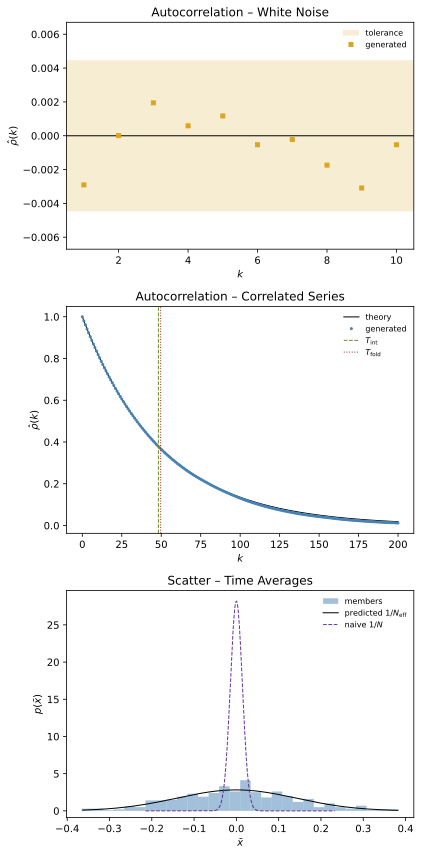

In [6]:
rng = rng_spawn(0)

N, M = 4000, 200
W = rng.standard_normal((N, M))
rho_w = ensemble_acf(W, maxlag=10)
assert abs(rho_w[0] - 1) < 1e-12 and np.all(np.abs(rho_w[1:]) < 4 / np.sqrt(N * M))

x = rng.standard_normal((7, 1))
direct = np.array([np.sum(x[: 7 - k, 0] * x[k:, 0]) / (7 - k) for k in range(5)])
assert np.allclose(ensemble_acov(x, 4), direct)

var_w, se_w = batched(lambda b: np.mean(b**2), W)
assert abs(var_w - 1) <= 3 * se_w

dt = 0.01
tau = dt * np.arange(2000)
fold2 = sc.optimize.brentq(lambda t: (1 + t) * np.exp(-t) - np.exp(-1), 1, 3)   # exact folding time of (1+tau)exp(-tau)
assert abs(integral_time(rho_w, 1.0) - 0.5) < 1e-12
assert abs(integral_time(np.exp(-tau), dt) - 1) < 1e-3 and abs(fold_time(np.exp(-tau), dt) - 1) < 1e-3
assert abs(integral_time((1 + tau) * np.exp(-tau), dt) - 2) < 1e-3 and abs(fold_time((1 + tau) * np.exp(-tau), dt) - fold2) < 1e-3

A = np.exp(-0.02)
Nt, Mm = 5000, 400
X = np.empty((Nt, Mm))
xx = rng.standard_normal(Mm)
for n in range(Nt):
    xx = A * xx + np.sqrt(1 - A**2) * rng.standard_normal(Mm)
    X[n] = xx
means = X.mean(axis=0)
var_pred = (1 + A) / (1 - A) / Nt
assert abs(means.var(ddof=1) / var_pred - 1) < 4 * np.sqrt(2 / (Mm - 1))   # relative error of a sample variance

lags = np.arange(201)
rho_x = ensemble_acf(X, maxlag=200)

tol = 4 / np.sqrt(N * M)

fig, ax = plt.subplots(3, 1, figsize=(6, 12))

ax[0].fill_between([0.5, 10.5], -tol, tol, color="goldenrod", alpha=0.2, lw=0, label="tolerance")
ax[0].axhline(0, color="k", lw=1)
ax[0].plot(np.arange(1, 11), rho_w[1:], "s", ms=4, color="goldenrod", label="generated")
ax[0].set(xlim=(0.5, 10.5), ylim=(-1.5 * tol, 1.5 * tol), xlabel="$k$", ylabel="$\\hat{\\rho}(k)$", title="Autocorrelation – White Noise")
ax[0].legend(fontsize=8, edgecolor="none")

ax[1].plot(lags, A**lags, "k-", lw=1, label="theory")
ax[1].plot(lags, rho_x, "o", color="steelblue", ms=2, label="generated")
ax[1].axvline(integral_time(rho_x, 1.0), color="olivedrab", ls="--", lw=1, label="$T_\\mathrm{int}$")
ax[1].axvline(fold_time(rho_x, 1.0), color="firebrick", ls=":", lw=1, label="$T_\\mathrm{fold}$")
ax[1].set(xlabel="$k$", ylabel="$\\hat{\\rho}(k)$", title="Autocorrelation – Correlated Series")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

grid = np.linspace(means.min(), means.max(), 600)
gauss = lambda v: np.exp(-grid**2 / (2 * v)) / np.sqrt(2 * np.pi * v)
ax[2].hist(means, bins=30, density=True, alpha=0.5, color="steelblue", label="members")
ax[2].plot(grid, gauss(var_pred), "k-", lw=1, label="predicted $1/N_\\mathrm{eff}$")
ax[2].plot(grid[120:-120], gauss(1 / Nt)[120:-120], "--", color="rebeccapurple", lw=1, label="naive $1/N$")
ax[2].set_ylim(-0.03 * ax[2].get_ylim()[1], ax[2].get_ylim()[1])
ax[2].set(xlabel="$\\bar{x}$", ylabel="$p(\\bar{x})$", title="Scatter – Time Averages")
ax[2].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

### 1. Continuous Autoregression

#### 1.1. CARMA

A broad family of stationary Gaussian processes follows from a linear differential equation driven by white noise

$$\alpha(D)\,x(t) = \beta(D)\,\varepsilon(t) \qquad D = \frac{d}{dt}$$

where the autoregressive and moving average polynomials

$$\alpha(s) = s^p + \alpha_{p-1}s^{p-1} + \dots + \alpha_1 s + \alpha_0 \qquad \beta(s) = \beta_0 + \beta_1 s + \dots + \beta_q s^q$$

act on $x$ and on the noise through the derivative operator $D$ and define the continuous autoregressive moving average model $\symup{CARMA}(p,q)$ of orders $p$ and $q$ with real coefficients. The noise is white with

$$\langle \varepsilon(t) \rangle = 0 \qquad \langle \varepsilon(t)\,\varepsilon(t^\prime) \rangle = \sigma_\varepsilon^2\,\delta(t-t^\prime)$$

and since only the product of $\sigma_\varepsilon$ and $\beta$ enters any statistic we fix $\beta_0 = 1$ without loss of generality. With the Fourier convention

$$\tilde{x}(f) = \int_{-\infty}^\infty x(t)\,e^{-2\pi i f t}\,dt$$

every derivative turns into a factor $2\pi i f$ so that the equation becomes algebraic

$$\alpha(2\pi i f)\,\tilde{x}(f) = \beta(2\pi i f)\,\tilde{\varepsilon}(f) \qquad \tilde{x}(f) = H(f)\,\tilde{\varepsilon}(f) \qquad H(f) = \frac{\beta(2\pi i f)}{\alpha(2\pi i f)}$$

with the transfer function $H$ acting as a linear filter on the noise. The noise itself has a flat spectrum, since inserting its correlation gives

$$\langle \tilde{\varepsilon}(f)\,\tilde{\varepsilon}^*(f^\prime) \rangle = \int\!\!\int \langle \varepsilon(t)\,\varepsilon(t^\prime) \rangle\,e^{-2\pi i f t}\,e^{2\pi i f^\prime t^\prime}\,dt\,dt^\prime = \sigma_\varepsilon^2 \int_{-\infty}^\infty e^{-2\pi i (f-f^\prime) t}\,dt = \sigma_\varepsilon^2\,\delta(f-f^\prime)$$

where the delta function in time collapses $t^\prime = t$ and the remaining integral is the Fourier representation of the delta function in frequency. Defining the power spectrum $S$ through $\langle \tilde{x}(f)\,\tilde{x}^*(f^\prime) \rangle = S(f)\,\delta(f-f^\prime)$ the filter enters squared

$$S(f) = |H(f)|^2\,\sigma_\varepsilon^2 = \sigma_\varepsilon^2\,\frac{|\beta(2\pi i f)|^2}{|\alpha(2\pi i f)|^2}$$

which is two sided and symmetric in $f$ for real coefficients and is related to the autocovariance by the Wiener-Khinchin theorem

$$S(f) = \int_{-\infty}^\infty C(\tau)\,e^{-2\pi i f\tau}\,d\tau \qquad C(\tau) = \int_{-\infty}^\infty S(f)\,e^{2\pi i f\tau}\,df$$

and to invert the spectrum we substitute $s = 2\pi i f$ so that the integral runs along the imaginary axis and use $|\alpha(2\pi i f)|^2 = \alpha(s)\,\alpha(-s)$ for real coefficients to find

$$C(\tau) = \frac{\sigma_\varepsilon^2}{2\pi i}\int_{-i\infty}^{i\infty} \frac{\beta(s)\,\beta(-s)}{\alpha(s)\,\alpha(-s)}\,e^{s\tau}\,ds$$

in which for $\tau > 0$ the factor $e^{s\tau}$ decays in the left half plane, so we close the contour there with a large semicircle whose contribution vanishes. If all roots $r_k$ of $\alpha$ satisfy $\symup{Re}\,r_k < 0$ they are exactly the enclosed poles while the roots of $\alpha(-s)$ lie outside, and the residue theorem for distinct roots gives

$$C(\tau) = \sum_{k=1}^p c_k\,e^{r_k|\tau|} \qquad c_k = \sigma_\varepsilon^2\,\frac{\beta(r_k)\,\beta(-r_k)}{\alpha^\prime(r_k)\,\alpha(-r_k)}$$

where the residue of $1/\alpha$ at a simple root is $1/\alpha^\prime(r_k)$ and the symmetry $C(-\tau) = C(\tau)$ extends the result to negative lags. The condition on the roots is the stationarity condition, since a root with positive real part would make the response to a single kick grow without bound. The autocovariance is therefore a sum of exponential modes, where real roots give pure decays and complex conjugate pairs give damped oscillations with conjugate weights so that the sum stays real. Every mode decays at the rate $|\symup{Re}\,r_k|$ and at large lags the slowest one dominates the envelope

$$T_\symup{env} = \frac{1}{\min_k |\symup{Re}\,r_k|}$$

while evaluating the Wiener-Khinchin theorem at zero frequency

$$S(0) = \int_{-\infty}^\infty C(\tau)\,d\tau = 2\,C(0)\,T_\symup{int}$$

links the integral time to the spectrum, where $\beta(0) = 1$ and $\alpha(0) = \alpha_0$ simplify the last step

$$T_\symup{int} = \frac{S(0)}{2\,C(0)} = \frac{\sigma_\varepsilon^2}{2\,C(0)\,\alpha_0^2}$$

and at high frequencies the leading powers dominate both polynomials

$$S(f) \simeq \sigma_\varepsilon^2\,\frac{\beta_q^2\,(2\pi f)^{2q}}{(2\pi f)^{2p}} \propto f^{-2(p-q)}$$

so the variance as the integral of the spectrum over all frequencies is finite only for $p > q$ which is why the definition requires $q < p$ in the first place. A derivative multiplies $\tilde{x}$ by $2\pi i f$ and the spectrum by $(2\pi f)^2$ so that the derivative has finite variance only if $2(p-q) - 2 > 1$ and since the orders are integers the paths are differentiable only for

$$p - q \geq 2$$

while they are continuous but nowhere differentiable otherwise. Finally, any $\symup{CARMA}(p,q)$ can be written as a first order equation for the vector $X$ of a latent process and its first $p-1$ derivatives

$$dX = \mathsf{A}\,X\,dt + \mathbf{e}\,\sigma_\varepsilon\,dW \qquad x = \mathbf{b}^\top X$$

with the companion matrix $\mathsf{A}$ that carries ones above the diagonal and the negative coefficients of $\alpha$ in its last row, the unit vector $\mathbf{e}$ along the last component and the vector $\mathbf{b}$ of coefficients of $\beta$ padded with zeros. Over a step $\Delta t$ this equation has the exact update

$$X_{n+1} = e^{\mathsf{A}\Delta t} X_n + \eta_n \qquad \langle \eta_n \eta_n^\top \rangle = \sigma_\varepsilon^2 \int_0^{\Delta t} e^{\mathsf{A}s}\,\mathbf{e}\,\mathbf{e}^\top e^{\mathsf{A}^\top s}\,ds$$

through the matrix exponential, which we state here without derivation.

In [7]:
def carma_roots(alpha):
    """roots of autoregressive polynomial, coefficients from constant term upwards without leading one"""
    return np.roots(np.r_[1.0, np.asarray(alpha, dtype=float)[::-1]])

def carma_psd(alpha, beta, sigma, f):
    """two sided power spectrum with noise amplitude sigma"""
    s = 2j * np.pi * np.asarray(f, dtype=float)
    a = np.polyval(np.r_[1.0, np.asarray(alpha, dtype=float)[::-1]], s)
    b = np.polyval(np.asarray(beta, dtype=float)[::-1], s)
    return sigma**2 * np.abs(b)**2 / np.abs(a)**2

def carma_acov(alpha, beta, sigma, tau):
    """autocovariance as sum of exponential modes, assumes distinct roots"""
    a = np.r_[1.0, np.asarray(alpha, dtype=float)[::-1]]
    b = np.asarray(beta, dtype=float)[::-1]
    r = np.roots(a)
    c = sigma**2 * np.polyval(b, r) * np.polyval(b, -r) / (np.polyval(np.polyder(a), r) * np.polyval(a, -r))
    tau = np.abs(np.asarray(tau, dtype=float))
    return np.real(np.exp(np.multiply.outer(tau, r)) @ c)

#### 1.2. First Order

The lowest order with $p = 1$ and $q = 0$ has a single root

$$\frac{dx}{dt} + \alpha_0\,x = \varepsilon(t) \qquad r = -\alpha_0$$

so its envelope time is $1/\alpha_0$ and from here on we call it $T$ and write $\alpha_0 = 1/T$ in all expressions. The weight of the single mode

$$C(0) = c = \frac{\sigma_\varepsilon^2}{\alpha^\prime(r)\,\alpha(-r)} = \frac{\sigma_\varepsilon^2}{2\alpha_0} = \frac{\sigma_\varepsilon^2\,T}{2}$$

is the stationary variance, which we call $\sigma^2$ so that a prescribed variance fixes the noise amplitude

$$\sigma_\varepsilon^2 = \frac{2\sigma^2}{T}$$

and writing the white noise as the increment of a Wiener process $\varepsilon\,dt = \sigma_\varepsilon\,dW$ with

$$\langle dW \rangle = 0 \qquad \langle dW^2 \rangle = dt$$

the equation becomes the Langevin equation

$$dx = -\frac{x}{T}\,dt + \sqrt{\frac{2\sigma^2}{T}}\,dW$$

whose first term relaxes $x$ towards zero on the timescale $T$ while the second term keeps kicking it. This process is known as the Ornstein-Uhlenbeck process in physics, as the damped random walk in the quasar variability literature and as $\symup{CAR}(1)$ in time series analysis.

#### 1.3. Solution

Multiplying by the integrating factor $e^{t/T}$ absorbs the drift term into a total differential

$$d\big(x\,e^{t/T}\big) = e^{t/T}\left(dx + \frac{x}{T}\,dt\right) = e^{t/T}\sqrt{\frac{2\sigma^2}{T}}\,dW$$

where no Itô correction appears since the factor is deterministic. Integrating from $t$ to $t + \Delta t$ and multiplying by $e^{-(t+\Delta t)/T}$ gives

$$x(t+\Delta t) = x(t)\,e^{-\Delta t/T} + \sqrt{\frac{2\sigma^2}{T}}\int_t^{t+\Delta t} e^{-(t+\Delta t-t^\prime)/T}\,dW(t^\prime)$$

where the stochastic integral is a weighted sum of independent Gaussian increments and therefore Gaussian with zero mean. Its variance follows from the Itô isometry

$$\left\langle \left(\int g\,dW\right)^2 \right\rangle = \int g^2\,dt^\prime$$

that holds because increments over disjoint intervals are uncorrelated, and the substitution $u = t + \Delta t - t^\prime$ gives

$$\frac{2\sigma^2}{T}\int_0^{\Delta t} e^{-2u/T}\,du = \sigma^2\left(1 - e^{-2\Delta t/T}\right)$$

and since the integral only contains increments after $t$ it is independent of $x(t)$ and of the integrals of all other steps. With independent standard normal draws $\xi_n$ we obtain the exact update

$$x_{n+1} = A\,x_n + \sigma\sqrt{1-A^2}\,\xi_n \qquad A = e^{-\Delta t/T}$$

which holds for any step size, since no approximation entered. The test series of the previous section is exactly this update with unit variance.

In [8]:
def ou_exact(T, sigma, dt, N, M, rng, x0=None):
    """exact update for M members over N steps, stationary start unless initial x given"""
    A = np.exp(-dt / T)
    x = sigma * rng.standard_normal(M) if x0 is None else np.full(M, float(x0))
    X = np.empty((N, M))
    for n in range(N):
        X[n] = x
        x = A * x + sigma * np.sqrt(1 - A**2) * rng.standard_normal(M)
    return X

#### 1.4. Statistics

The update has the stationary variance as its fixed point

$$\langle x_{n+1}^2 \rangle = A^2 \langle x_n^2 \rangle + \sigma^2\left(1-A^2\right) \qquad \langle x^2 \rangle = \sigma^2$$

and multiplying the solution over a lag $\tau > 0$ by $x(t)$ and averaging removes the noise integral, since it is independent of the past

$$C(\tau) = \langle x(t+\tau)\,x(t) \rangle = e^{-\tau/T}\langle x(t)^2 \rangle = \sigma^2 e^{-|\tau|/T} \qquad \rho(\tau) = e^{-|\tau|/T}$$

which is the single mode of the general result with weight $\sigma^2$ and root $-1/T$ as it should be. All three timescales coincide

$$T_\symup{int} = \int_0^\infty e^{-\tau/T}\,d\tau = T \qquad e^{-T_\symup{fold}/T} = e^{-1} \qquad T_\symup{fold} = T \qquad T_\symup{env} = \frac{1}{|r|} = T$$

while the sampled autocorrelation $\rho(k) = A^k$ turns the trapezoidal sum of the integral time into a geometric series

$$\Delta t\left(\frac{1}{2} + \sum_{k=1}^\infty A^k\right) = \frac{\Delta t}{2}\,\frac{1+A}{1-A} = \frac{\Delta t}{2}\coth\frac{\Delta t}{2T} \approx T\left(1 + \frac{\Delta t^2}{12\,T^2}\right)$$

so the discrete estimate overshoots by a relative amount quadratic in the step. Since $x$ is a linear combination of Gaussian increments it is Gaussian itself and has the kurtosis $\langle x^4 \rangle / \langle x^2 \rangle^2 = 3$ at every time.

#### 1.5. Relaxation

Starting from a fixed value $x_0$ at $t = 0$ instead of the stationary distribution, the solution over the full interval gives

$$\langle x(t) \rangle = x_0\,e^{-t/T} \qquad \symup{Var}\,x(t) = \sigma^2\left(1 - e^{-2t/T}\right)$$

so the mean forgets the start over $T$ while the variance builds up twice as fast. Drawing $x_0$ from a normal distribution with variance $\sigma^2$ instead adds the decayed initial variance

$$\sigma^2 e^{-2t/T} + \sigma^2\left(1 - e^{-2t/T}\right) = \sigma^2$$

which is stationary from the first step on, so a forcing field is either initialized from the stationary distribution or run through a burn in of several correlation times before it is used.

#### 1.6. Structure Function

Light curves are irregularly sampled with an unknown mean, so the quasar literature works with increments rather than with the autocovariance. Expanding the square and using stationarity, the squared structure function becomes

$$\symup{SF}^2(\tau) = \langle (x(t+\tau) - x(t))^2 \rangle = 2\,C(0) - 2\,C(\tau) = 2\sigma^2\left(1 - e^{-|\tau|/T}\right)$$

which does not depend on the mean by construction. At short lags expanding the exponential gives

$$\symup{SF}^2(\tau) \approx \frac{2\sigma^2}{T}\,\tau \qquad \tau \ll T$$

which grows linearly like a random walk, while at long lags the two values become uncorrelated with the structure function saturating at

$$\symup{SF}_\infty^2 = 2\sigma^2$$

and a random walk that is damped beyond $T$ explains the name, while the literature quotes the pair $\tau_\symup{\,DRW} = T$ and $\symup{SF}_\infty = \sqrt{2}\,\sigma$ instead of our pair to parametrize the same process.

In [9]:
def ensemble_sf(X, lags):
    """squared structure function at integer lags, averaged over time and members"""
    return np.array([np.mean((X[k:] - X[:-k])**2) if k > 0 else 0.0 for k in lags])

#### 1.7. Spectrum

Inserting the first order polynomials into the general spectrum gives the Lorentzian

$$S(f) = \frac{\sigma_\varepsilon^2}{(2\pi f)^2 + 1/T^2} = \frac{2\sigma^2 T}{1 + (2\pi f T)^2}$$

which is flat at $S(0) = 2\sigma^2 T$ below the break frequency

$$f_\symup{b} = \frac{1}{2\pi T}$$

and falls as $f^{-2}$ above it, matching $p - q = 1$ with continuous but nowhere differentiable paths. The plateau reproduces $T_\symup{int} = S(0)/2\sigma^2 = T$ as well. The sampled sequence only resolves frequencies up to the Nyquist frequency $1/2\Delta t$ and its spectrum follows from the discrete version of the Wiener-Khinchin theorem with $\omega = 2\pi f\Delta t$

$$S_\symup{d}(f) = \Delta t \sum_{k=-\infty}^\infty \sigma^2 A^{|k|} e^{-i\omega k} = \Delta t\,\sigma^2\left(\frac{1}{1 - A e^{-i\omega}} + \frac{A e^{i\omega}}{1 - A e^{i\omega}}\right) = \frac{\Delta t\,\sigma^2 \left(1 - A^2\right)}{|1 - A e^{-i\omega}|^2}$$

where the two geometric series cover the non negative and the negative lags and combine over their common denominator. Expanding for $\Delta t \ll T$ with $A \approx 1 - \Delta t/T$ and $\omega \ll 1$ recovers the Lorentzian

$$|1 - A e^{-i\omega}|^2 \approx \frac{\Delta t^2}{T^2} + \omega^2 \qquad S_\symup{d}(f) \approx \frac{2\sigma^2\Delta t^2/T}{\Delta t^2/T^2 + (2\pi f \Delta t)^2} = S(f)$$

while close to the Nyquist frequency the discrete spectrum lies above it, since sampling folds the power of all frequencies beyond Nyquist back into the resolved band

$$S_\symup{d}(f) = \sum_{m=-\infty}^\infty S\!\left(f + \frac{m}{\Delta t}\right)$$

and from data we estimate the spectrum with the periodogram of each member

$$P(f_j) = \frac{\Delta t}{N}\left|\sum_{n=0}^{N-1} x_n\,e^{-2\pi i j n/N}\right|^2 \qquad f_j = \frac{j}{N\Delta t}$$

whose expectation approaches the discrete spectrum once the duration is much longer than the correlation time. Its real and imaginary parts are Gaussian with equal variance, so $P$ is exponentially distributed with a standard deviation equal to its mean at every frequency. A single periodogram therefore never converges, and averaging over the $M$ members leaves a relative scatter of $1/\sqrt{M}$ per frequency except at zero and at Nyquist where the sum is real.

In [10]:
def ensemble_psd(X, dt):
    """two sided periodogram averaged over members, on non negative frequencies"""
    N = X.shape[0]
    P = dt / N * np.abs(np.fft.rfft(X, axis=0))**2
    return np.fft.rfftfreq(N, dt), P.mean(axis=1)

#### 1.8. Tests

We simulate a stationary ensemble with the exact update and compare every statistic of this section with its prediction, using batch means over members as error bars. The integral time is compared to the trapezoidal value including its step correction, the periodogram to the discrete spectrum away from zero and Nyquist frequency, and a relaxing ensemble to the mean and variance from a fixed start at every time. The general spectrum and autocovariance are additionally checked against each other through the Wiener-Khinchin theorem for a higher order polynomial with a complex pair of roots, which tests the residue formula beyond the single mode.

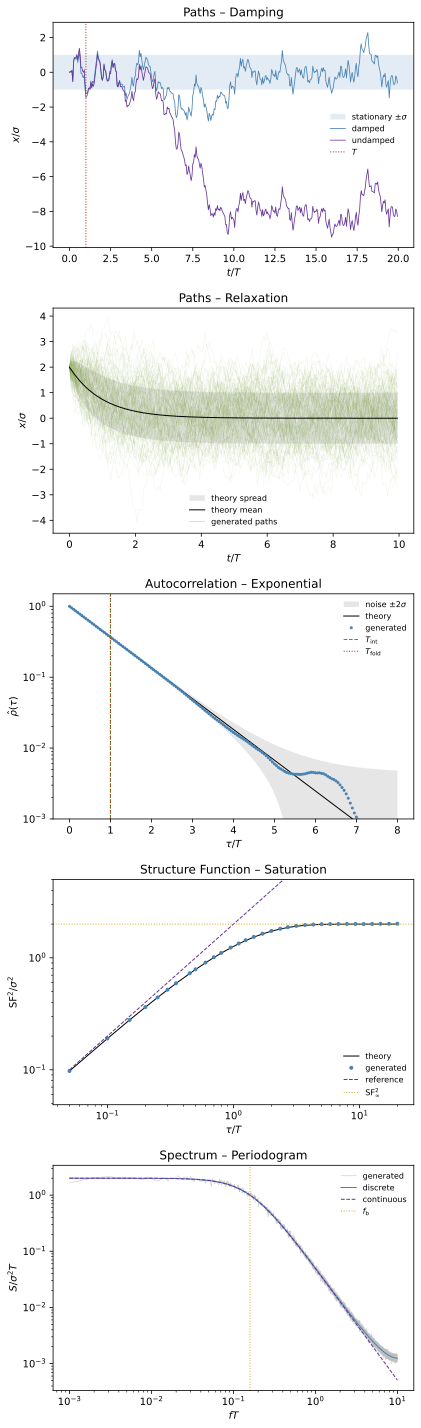

In [11]:
rng = rng_spawn(1)

T, sigma, dt = 1.0, 1.0, 0.05
N, M = 20000, 200
A = np.exp(-dt / T)
X = ou_exact(T, sigma, dt, N, M, rng)

var, se = batched(lambda b: np.mean(b**2), X)
assert abs(var - sigma**2) <= 3 * se
kurt, se = batched(lambda b: np.mean(b**4) / np.mean(b**2)**2, X)
assert abs(kurt - 3) <= 3 * se

kT, maxlag = int(round(T / dt)), int(round(8 * T / dt))
r1, se = batched(lambda b: ensemble_acf(b, kT)[kT], X)
assert abs(r1 - np.exp(-1)) <= 3 * se
t_int, se = batched(lambda b: integral_time(ensemble_acf(b, maxlag), dt), X)
assert abs(t_int - dt / 2 / np.tanh(dt / (2 * T))) <= 3 * se   # trapezoidal value with step correction
t_fold, se = batched(lambda b: fold_time(ensemble_acf(b, maxlag), dt), X)
assert abs(t_fold - T) <= 3 * se
sf1, se = batched(lambda b: ensemble_sf(b, [kT])[0], X)
assert abs(sf1 - 2 * sigma**2 * (1 - np.exp(-1))) <= 3 * se

alpha1, beta1, sig_eps = [1 / T], [1.0], np.sqrt(2 * sigma**2 / T)
assert np.isclose(carma_acov(alpha1, beta1, sig_eps, 0.0), sigma**2)
assert np.isclose(carma_psd(alpha1, beta1, sig_eps, 0.0) / (2 * sigma**2), T)
assert np.isclose(1 / np.min(np.abs(carma_roots(alpha1).real)), T)

alpha3, beta3 = np.poly([-1.0, -0.2 + 2j, -0.2 - 2j]).real[:0:-1], [1.0, 0.5]   # stable roots with a complex pair
f_peak = 2 / (2 * np.pi)
var3 = 2 * (sc.integrate.quad(lambda f: carma_psd(alpha3, beta3, 1.0, f), 0, 1, points=[f_peak], limit=500)[0]
            + sc.integrate.quad(lambda f: carma_psd(alpha3, beta3, 1.0, f), 1, np.inf, limit=500)[0])
s03 = 2 * sc.integrate.quad(lambda t: carma_acov(alpha3, beta3, 1.0, t), 0, 200, limit=2000)[0]
assert np.isclose(var3, carma_acov(alpha3, beta3, 1.0, 0.0), rtol=1e-6)
assert np.isclose(s03, carma_psd(alpha3, beta3, 1.0, 0.0), rtol=1e-6)

x0, Mr = 2 * sigma, 2000
Xr = ou_exact(T, sigma, dt, int(round(10 * T / dt)), Mr, rng, x0=x0)
t = dt * np.arange(Xr.shape[0])
m_th, v_th = x0 * np.exp(-t / T), sigma**2 * (1 - np.exp(-2 * t / T))
assert np.all(np.abs(Xr.mean(axis=1) - m_th)[1:] <= 4.5 * np.sqrt(v_th[1:] / Mr))
assert np.all(np.abs(Xr.var(axis=1, ddof=1)[1:] / v_th[1:] - 1) <= 4.5 * np.sqrt(2 / (Mr - 1)))

f, P = ensemble_psd(X, dt)
S_d = dt * sigma**2 * (1 - A**2) / np.abs(1 - A * np.exp(-2j * np.pi * f * dt))**2
ratio = (P / S_d)[1:-1]                                         # drop zero and Nyquist frequency
assert abs(ratio.mean() - 1) <= 4 / np.sqrt(M * len(ratio)) and np.all(np.abs(ratio - 1) <= 6 / np.sqrt(M))

lags = np.arange(maxlag + 1)
rho = ensemble_acf(X, maxlag)
lags_sf = np.unique(np.round(np.logspace(0, np.log10(20 * T / dt), 40)).astype(int))
sf = ensemble_sf(X, lags_sf)

Nw = int(round(20 * T / dt))
xi = sigma * np.sqrt(1 - A**2) * rng.standard_normal(Nw)   # shared increments for both paths
drw, walk = np.zeros(Nw), np.zeros(Nw)
for n in range(1, Nw):
    drw[n] = A * drw[n - 1] + xi[n - 1]
    walk[n] = walk[n - 1] + xi[n - 1]
tw = dt * np.arange(Nw)

fig, ax = plt.subplots(5, 1, figsize=(6, 20))

ax[0].axhspan(-sigma, sigma, color="steelblue", alpha=0.15, lw=0, label="stationary $\\pm\\sigma$")
ax[0].plot(tw / T, drw / sigma, color="steelblue", lw=0.8, label="damped")
ax[0].plot(tw / T, walk / sigma, color="rebeccapurple", lw=0.8, label="undamped")
ax[0].axvline(1, color="firebrick", ls=":", lw=1, label="$T$")
ax[0].set(xlabel="$t/T$", ylabel="$x/\\sigma$", title="Paths – Damping")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9)

ax[1].fill_between(t / T, (m_th - np.sqrt(v_th)) / sigma, (m_th + np.sqrt(v_th)) / sigma, color="k", alpha=0.1, lw=0, label="theory spread")
ax[1].plot(t / T, Xr[:, :100] / sigma, color="olivedrab", lw=0.5, alpha=0.1, rasterized=False)
ax[1].plot(t / T, m_th / sigma, "k-", lw=1, label="theory mean")
ax[1].plot([], [], color="olivedrab", lw=0.5, alpha=0.5, label="generated paths")
ax[1].set(xlabel="$t/T$", ylabel="$x/\\sigma$", title="Paths – Relaxation")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

pos = rho > 0

sig_rho = np.sqrt((1 + A**2) / ((1 - A**2) * N * M))   # large lag scatter of the estimator
ax[2].fill_between(lags * dt / T, np.maximum(A**lags - 2 * sig_rho, 1e-4), A**lags + 2 * sig_rho, color="k", alpha=0.1, lw=0, label="noise $\\pm 2\\sigma$")
ax[2].semilogy(lags * dt / T, A**lags, "k-", lw=1, label="theory")
ax[2].semilogy(lags[pos] * dt / T, rho[pos], "o", color="steelblue", ms=2, label="generated")
ax[2].axvline(t_int / T, color="olivedrab", ls="--", lw=1, label="$T_\\mathrm{int}$")
ax[2].axvline(t_fold / T, color="firebrick", ls=":", lw=1, label="$T_\\mathrm{fold}$")
ax[2].set(xlabel="$\\tau/T$", ylabel="$\\hat{\\rho}(\\tau)$", ylim=(1e-3, 1.5), title="Autocorrelation – Exponential")
ax[2].legend(fontsize=8, edgecolor="none", handlelength=1.9)

tau_sf = lags_sf * dt
ax[3].loglog(tau_sf / T, 2 * (1 - np.exp(-tau_sf / T)), "k-", lw=1, label="theory")
ax[3].loglog(tau_sf / T, sf / sigma**2, "o", color="steelblue", ms=3, label="generated")
ax[3].loglog(tau_sf / T, 2 * tau_sf / T, "--", color="rebeccapurple", lw=1, label="reference")
ax[3].axhline(2, color="goldenrod", ls=":", lw=1, label="$\\mathrm{SF}_\\infty^2$")
ax[3].set(xlabel="$\\tau/T$", ylabel="$\\mathrm{SF}^2/\\sigma^2$", ylim=(0.5 * sf[0] / sigma**2, 5), title="Structure Function – Saturation")
ax[3].legend(fontsize=8, edgecolor="none", handlelength=1.9)

ax[4].loglog(f[1:] * T, P[1:] / (sigma**2 * T), color="k", lw=0.5, alpha=0.25, label="generated")
ax[4].loglog(f[1:] * T, S_d[1:] / (sigma**2 * T), "-", color="steelblue", lw=1, label="discrete")
ax[4].loglog(f[1:] * T, carma_psd(alpha1, beta1, sig_eps, f[1:]) / (sigma**2 * T), "--", color="rebeccapurple", lw=1, label="continuous")
ax[4].axvline(1 / (2 * np.pi), color="goldenrod", ls=":", lw=1, label="$f_\\mathrm{b}$")
ax[4].set(xlabel="$fT$", ylabel="$S/\\sigma^2 T$", title="Spectrum – Periodogram")
ax[4].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

### 2. Time Stepping

#### 2.1. Order

The word order appears in two unrelated meanings that are easily confused. The order of a process counts the derivatives in its defining equation, so $p$ and $q$ of the previous section are properties of the model that set its spectral slope and its smoothness. The order of a scheme describes how fast the numerical error of an approximate solution shrinks with the time step, so a higher order scheme solves the same model more accurately while a higher order process is a different model altogether. Both are independent of each other and any scheme can be applied to a process of any order. For stochastic equations the order of a scheme further splits into two kinds, where the strong order $\gamma$ bounds the error of individual paths at a fixed time $t_n = n\Delta t$

$$\left\langle |x_n - x(t_n)| \right\rangle \leq K\,\Delta t^\gamma$$

when the approximate and the true path are driven by the same noise, while the weak order $\beta$ bounds the error of expectations of smooth functions $g$ of the state

$$\left| \langle g(x_n) \rangle - \langle g(x(t_n)) \rangle \right| \leq K\,\Delta t^\beta$$

with a constant $K$ that does not depend on the step. A forcing field enters a simulation through its statistics and not through one particular path, so the relevant measure for us is the weak error, and since we compare stationary variances and correlation times we measure its limit at late times.

#### 2.2. Recursion

The Langevin equation of the previous section contains a single timescale, so the only dimensionless parameter of a discretization is the step in units of the correlation time

$$h = \frac{\Delta t}{T}$$

and every linear one step scheme maps the state onto a recursion of the same form as the exact update

$$x_{n+1} = a\,x_n + b\,\xi_n$$

with independent standard normal draws $\xi_n$ and coefficients $a$ and $b$ that depend on the scheme and on $h$ where $b$ also carries the amplitude $\sigma$ of the noise. Iterating the variance from any start

$$\langle x_n^2 \rangle = a^{2n} \langle x_0^2 \rangle + b^2 \sum_{m=0}^{n-1} a^{2m} = a^{2n} \langle x_0^2 \rangle + b^2\,\frac{1 - a^{2n}}{1 - a^2}$$

shows that the recursion is stable only for $|a| < 1$ in which case it approaches the stationary variance

$$v = \frac{b^2}{1 - a^2}$$

while it grows without bound otherwise. As for the test series of the preamble the autocorrelation follows from multiplying the recursion by $x_{n+1-k}$ and averaging

$$\rho(k) = a^k$$

so a negative $a$ produces an autocorrelation that changes sign at every step, and its envelope $|a|^k$ decays exponentially in the lag which defines the envelope time through

$$|a|^k = e^{-k\Delta t/T_\symup{env}} \qquad T_\symup{env} = -\frac{\Delta t}{\ln|a|}$$

which together with the variance gives the two error ratios

$$\frac{v}{\sigma^2} = \frac{b^2}{\sigma^2\left(1 - a^2\right)} \qquad \frac{T_\symup{env}}{T} = -\frac{h}{\ln|a|}$$

that both equal one for the exact coefficients of the previous section and that we evaluate for every scheme. The discrete spectrum of the previous section carries over with $\sigma^2(1 - A^2)$ replaced by $b^2$

$$S_\symup{d}(f) = \frac{b^2\,\Delta t}{|1 - a\,e^{-i\omega}|^2}$$

which at the Nyquist frequency $\omega = \pi$ becomes $b^2\Delta t/(1 + a)^2$ and diverges as $a$ approaches minus one, so an instability first shows up as power piling up at the shortest resolved period.

#### 2.3. Schemes

Every scheme sees the noise through the Wiener increment $\Delta W_n$ over one step, which is the standard normal draw $\xi_n$ scaled to the variance $\Delta t$ so that the noise term of the Langevin equation contributes

$$\sqrt{\frac{2\sigma^2}{T}}\,\Delta W_n = \sigma\sqrt{2h}\,\xi_n$$

per step, while the schemes differ in how they treat the drift and the noise over the step.

##### 2.3.1. Euler-Maruyama

Evaluates the drift at the start of the step

$$x_{n+1} = x_n - h\,x_n + \sigma\sqrt{2h}\,\xi_n \qquad a = 1 - h \qquad b = \sigma\sqrt{2h}$$

which gives the variance ratio

$$\frac{v}{\sigma^2} = \frac{2h}{1 - (1-h)^2} = \frac{2h}{2h - h^2} = \frac{1}{1 - h/2}$$

that is too large for every step and diverges at $h = 2$ where $a$ reaches minus one, while the autocorrelation already alternates in sign for $1 < h < 2$ since the coefficient is negative there. The Milstein correction adds a term proportional to the derivative of the noise amplitude with respect to the state, which vanishes for additive noise, so here both schemes coincide and the strong order of this scheme rises from one half to one.

##### 2.3.2. Heun

Predicts the end of the step with the previous scheme and corrects with the average of the drift at both ends

$$\tilde{x} = x_n - h\,x_n + \sigma\sqrt{2h}\,\xi_n \qquad x_{n+1} = x_n - \frac{h}{2}\left(x_n + \tilde{x}\right) + \sigma\sqrt{2h}\,\xi_n$$

where predictor and corrector use the same draw $\xi_n$ and inserting the predictor collects the terms of $x_n$ and $\xi_n$

$$x_{n+1} = \left(1 - h + \frac{h^2}{2}\right) x_n + \left(1 - \frac{h}{2}\right)\sigma\sqrt{2h}\,\xi_n$$

so that with $1 - a^2 = 2h(1 - h + h^2/2 - h^3/8)$ the variance ratio becomes

$$\frac{v}{\sigma^2} = \frac{1 - h + h^2/4}{1 - h + h^2/2 - h^3/8}$$

whose numerator and denominator agree up to first order in the step, while $a = 1 - h + h^2/2$ has no real roots and therefore stays positive and lies below one for $0 < h < 2$ which bounds the stable steps.

##### 2.3.3. Crank-Nicolson

Averages the drift over the old and the new state

$$x_{n+1} - x_n = -\frac{h}{2}\left(x_n + x_{n+1}\right) + \sigma\sqrt{2h}\,\xi_n$$

and solving for the new state gives

$$a = \frac{1 - h/2}{1 + h/2} \qquad b = \frac{\sigma\sqrt{2h}}{1 + h/2} \qquad 1 - a^2 = \frac{(1 + h/2)^2 - (1 - h/2)^2}{(1 + h/2)^2} = \frac{2h}{(1 + h/2)^2}$$

so the variance ratio is exactly one for every step and since $|a| < 1$ for all $h > 0$ the scheme is unconditionally stable. Its coefficient is however only the lowest Padé approximation of $e^{-h}$ so the correlation time is wrong, and beyond $h = 2$ the coefficient turns negative and the autocorrelation oscillates while the variance stays exact. A correct variance therefore says nothing about a correct time correlation.

##### 2.3.4. Exponential Euler

Integrates the drift exactly but keeps the naive noise increment

$$a = e^{-h} \qquad b = \sigma\sqrt{2h} \qquad \frac{v}{\sigma^2} = \frac{2h}{1 - e^{-2h}}$$

so it has the exact correlation time but a variance that is too large for every step, which mirrors the previous scheme and shows that the noise term needs the same care as the drift.

##### 2.3.5. Exact

Stepping from the previous section has the coefficients

$$a = e^{-h} \qquad b = \sigma\sqrt{1 - e^{-2h}}$$

with both ratios equal to one for any step, which makes it the reference for all others.

In [12]:
def scheme_coeffs(name, h, sigma):
    """coefficients a and b of one step for given scheme"""
    h = np.asarray(h, dtype=float)
    if name == "exact":
        return np.exp(-h), sigma * np.sqrt(1 - np.exp(-2 * h))
    if name == "euler_maruyama":
        return 1 - h, sigma * np.sqrt(2 * h)
    if name == "heun":
        return 1 - h + h**2 / 2, sigma * np.sqrt(2 * h) * (1 - h / 2)
    if name == "crank_nicolson":
        return (1 - h / 2) / (1 + h / 2), sigma * np.sqrt(2 * h) / (1 + h / 2)
    if name == "exponential_euler":
        return np.exp(-h), sigma * np.sqrt(2 * h)
    raise ValueError(f"unknown scheme {name}")

def error_ratios(name, h, sigma=1.0):
    """variance ratio and envelope time ratio of a scheme"""
    a, b = scheme_coeffs(name, h, sigma)
    return b**2 / (sigma**2 * (1 - a**2)), -np.asarray(h) / np.log(np.abs(a))

def run_scheme(name, T, sigma, dt, N, M, rng, x0=None):
    """recursion of given scheme for M members over N steps, dt scalar or one per step"""
    dt = np.broadcast_to(np.asarray(dt, dtype=float), (N,))
    a, b = scheme_coeffs(name, dt / T, sigma)
    x = sigma * rng.standard_normal(M) if x0 is None else np.full(M, float(x0))
    X = np.empty((N, M))
    for n in range(N):
        X[n] = x
        x = a[n] * x + b[n] * rng.standard_normal(M)
    return X

#### 2.4. Errors

Expanding the logarithms of the coefficients for small steps

$$\ln(1 - h) = -h - \frac{h^2}{2} - \dots \qquad \ln\!\left(1 - h + \frac{h^2}{2}\right) = -h + \frac{h^3}{6} + \dots \qquad \ln\frac{1 - h/2}{1 + h/2} = -2\,\symup{artanh}\frac{h}{2} = -h - \frac{h^3}{12} - \dots$$

where the middle coefficient differs from $e^{-h}$ only at third order, and inserting them together with the expanded variance ratios into the error ratios gives the leading errors

$$\begin{align*}
\text{Euler-Maruyama} &\qquad \frac{v}{\sigma^2} \approx 1 + \frac{h}{2} &&\qquad \frac{T_\symup{env}}{T} \approx 1 - \frac{h}{2} \\
\text{Heun} &\qquad \frac{v}{\sigma^2} \approx 1 - \frac{h^2}{4} &&\qquad \frac{T_\symup{env}}{T} \approx 1 + \frac{h^2}{6} \\
\text{Crank-Nicolson} &\qquad \frac{v}{\sigma^2} = 1 &&\qquad \frac{T_\symup{env}}{T} \approx 1 - \frac{h^2}{12} \\
\text{Exponential Euler} &\qquad \frac{v}{\sigma^2} \approx 1 + h &&\qquad \frac{T_\symup{env}}{T} = 1
\end{align*}$$

so the leading powers reproduce the weak orders, one for Euler-Maruyama and exponential Euler and two for Heun and Crank-Nicolson, while the exact update has no error and therefore no order at all. At large steps the expansions fail and only the closed forms hold, where the coefficient of Euler-Maruyama vanishes at $h = 1$ and the one of Crank-Nicolson at $h = 2$ so that the envelope time collapses to zero before the autocorrelation starts to oscillate.

#### 2.5. Variable Steps

In a simulation the time step changes from step to step through the Courant condition, so the coefficients become $a_n$ and $b_n$ evaluated at $h_n = \Delta t_n/T$ and the variance follows the map

$$v_{n+1} = a_n^2\,v_n + b_n^2$$

with a fixed point that moves whenever the step changes. For the exact coefficients the map keeps the stationary variance

$$e^{-2h_n}\sigma^2 + \sigma^2\left(1 - e^{-2h_n}\right) = \sigma^2$$

for any sequence of steps, and two consecutive steps combine into a single step of the summed length

$$e^{-h_1}e^{-h_2} = e^{-(h_1 + h_2)} \qquad \sigma^2\left(1 - e^{-2h_1}\right)e^{-2h_2} + \sigma^2\left(1 - e^{-2h_2}\right) = \sigma^2\left(1 - e^{-2(h_1 + h_2)}\right)$$

so the exact update produces the same statistics regardless of how the time axis is cut. Every other scheme chases a stationary variance that depends on the current step, so its forcing amplitude becomes modulated by the time step and correlated with whatever controls the Courant condition, which is an artificial coupling between the forcing and the flow.

#### 2.6. Tests

We run every scheme at several steps and compare the measured variance and lag one autocorrelation with the stationary variance and the coefficient $a$ of the recursion, using batch means as error bars with more batches than before so that the standard errors themselves are well determined, and a wider deviation threshold since many checks are combined. The closed forms are checked against the small step expansions, which verifies the weak orders, and at large steps Crank-Nicolson is checked for its exact variance while Euler-Maruyama is checked for its divergence. Finally a random sequence of steps tests the variance map for the exact update and for Euler-Maruyama.

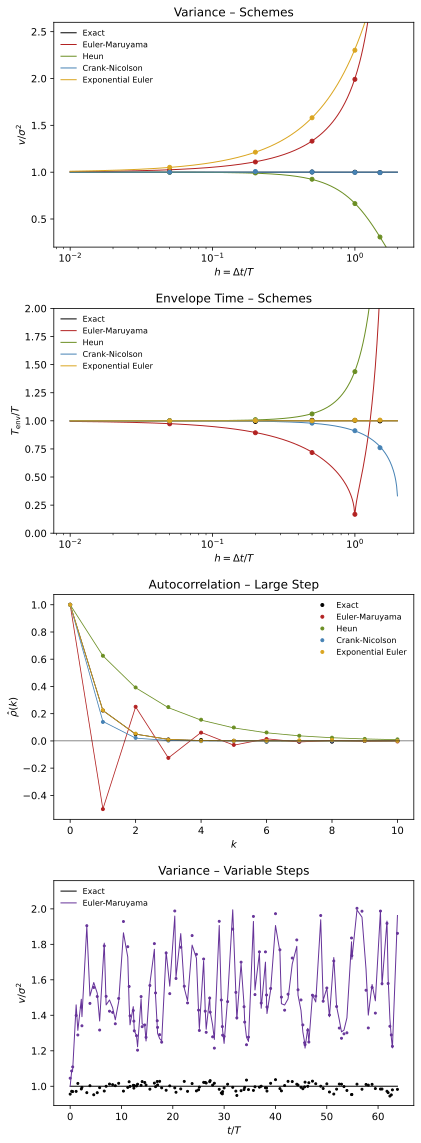

In [13]:
rng = rng_spawn(2)

T, sigma, M = 1.0, 1.0, 200
names = ["exact", "euler_maruyama", "heun", "crank_nicolson", "exponential_euler"]
hs = [0.05, 0.2, 0.5, 1.0, 1.5]
res, rho_big = {}, {}
for name in names:
    for h in hs:
        a, b = scheme_coeffs(name, h, sigma)
        burn = int(np.ceil(10 / h))   # discard relaxation from the initial variance
        X = run_scheme(name, T, sigma, h * T, burn + int(1000 / h), M, rng)[burn:]
        v, se_v = batched(lambda Xb: np.mean(Xb**2), X, B=40)
        r1, se_r = batched(lambda Xb: ensemble_acf(Xb, 1)[1], X, B=40)
        assert abs(v - b**2 / (1 - a**2)) <= 4 * se_v and abs(r1 - a) <= 4 * se_r
        res[name, h] = v, r1
        if h == 1.5:
            rho_big[name] = ensemble_acf(X, 10)

a, b = scheme_coeffs("crank_nicolson", 4.0, sigma)
X = run_scheme("crank_nicolson", T, sigma, 4.0 * T, 5000, M, rng)
v, se_v = batched(lambda Xb: np.mean(Xb**2), X, B=40)
r1, se_r = batched(lambda Xb: ensemble_acf(Xb, 1)[1], X, B=40)
assert a < 0 and abs(v - sigma**2) <= 4 * se_v and abs(r1 - a) <= 4 * se_r
X = run_scheme("euler_maruyama", T, sigma, 2.5 * T, 30, M, rng)
assert np.mean(X[-1]**2) > 1e8 * sigma**2

h0 = 1e-3
for name, cv, pv, ct, pt in [("euler_maruyama", 1 / 2, 1, -1 / 2, 1), ("heun", -1 / 4, 2, 1 / 6, 2),
                             ("crank_nicolson", 0, 1, -1 / 12, 2), ("exponential_euler", 1, 1, 0, 1), ("exact", 0, 1, 0, 1)]:
    rv, rt = error_ratios(name, h0)
    assert np.isclose((rv - 1) / h0**pv, cv, rtol=1e-2, atol=1e-6) and np.isclose((rt - 1) / h0**pt, ct, rtol=1e-2, atol=1e-6)

Nv, Mv = 120, 4000
dts = T * rng.uniform(0.05, 1.0, Nv)
var_map = {}
for name in ["exact", "euler_maruyama"]:
    a, b = scheme_coeffs(name, dts / T, sigma)
    v_th = np.empty(Nv)
    v_th[0] = sigma**2
    for n in range(Nv - 1):
        v_th[n + 1] = a[n]**2 * v_th[n] + b[n]**2
    v_meas = np.mean(run_scheme(name, T, sigma, dts, Nv, Mv, rng)**2, axis=1)
    assert np.all(np.abs(v_meas / v_th - 1) <= 4.5 * np.sqrt(2 / Mv))
    var_map[name] = v_th, v_meas
assert np.allclose(var_map["exact"][0], sigma**2)

colors = {"exact": "k", "euler_maruyama": "firebrick", "heun": "olivedrab", "crank_nicolson": "steelblue", "exponential_euler": "goldenrod"}
labels = {"exact": "Exact", "euler_maruyama": "Euler-Maruyama", "heun": "Heun", "crank_nicolson": "Crank-Nicolson", "exponential_euler": "Exponential Euler"}
hg = np.logspace(-2, np.log10(1.99), 400)
k = np.arange(11)
tv = np.r_[0.0, np.cumsum(dts)[:-1]]

fig, ax = plt.subplots(4, 1, figsize=(6, 16))
for name in names:
    rv, rt = error_ratios(name, hg)
    ax[0].plot(hg, rv, color=colors[name], lw=1, label=labels[name])
    ax[0].plot(hs, [res[name, h][0] / sigma**2 for h in hs], "o", color=colors[name], ms=4)
    ax[1].plot(hg, rt, color=colors[name], lw=1, label=labels[name])
    ax[1].plot(hs, [-h / np.log(abs(res[name, h][1])) for h in hs], "o", color=colors[name], ms=4)
    ax[2].plot(k, scheme_coeffs(name, 1.5, sigma)[0]**k, "-", color=colors[name], lw=0.8)
    ax[2].plot(k, rho_big[name], "o", color=colors[name], ms=3, label=labels[name])
ax[0].set(xscale="log", ylim=(0.2, 2.6), xlabel="$h = \\Delta t/T$", ylabel="$v/\\sigma^2$", title="Variance – Schemes")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9)
ax[1].set(xscale="log", ylim=(0, 2), xlabel="$h = \\Delta t/T$", ylabel="$T_\\mathrm{env}/T$", title="Envelope Time – Schemes")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)
ax[2].axhline(0, color="k", lw=0.5)
ax[2].set(xlabel="$k$", ylabel="$\\hat{\\rho}(k)$", title="Autocorrelation – Large Step")
ax[2].legend(fontsize=8, edgecolor="none", handlelength=1.9)

for name in ["exact", "euler_maruyama"]:
    v_th, v_meas = var_map[name]
    ax[3].plot(tv / T, v_meas / sigma**2, "o", color="rebeccapurple" if name == "euler_maruyama" else colors[name], ms=2)
    ax[3].plot(tv / T, v_th / sigma**2, "-", color="rebeccapurple" if name == "euler_maruyama" else colors[name], lw=1, label=labels[name])
ax[3].set(xlabel="$t/T$", ylabel="$v/\\sigma^2$", title="Variance – Variable Steps")
ax[3].set_ylim(ax[3].get_ylim()[0], 1.05 * ax[3].get_ylim()[1])
ax[3].legend(fontsize=8, edgecolor="none", handlelength=1.9, facecolor="none")

fig.tight_layout()
plt.show()

### 3. Forcing Field

#### 3.1. Modes

A forcing field drives the flow on large scales with a prescribed spatial structure and with the time correlation of the previous sections. In a periodic box of side $L$ in $D$ dimensions the field is a Fourier series over the wavevectors $\mathbf{k} = 2\pi\mathbf{n}/L$ with integer vectors $\mathbf{n}$

$$\mathbf{f}(\mathbf{x},t) = \sum_{\mathbf{k}} \hat{\mathbf{f}}_\mathbf{k}(t)\,e^{i\mathbf{k}\cdot\mathbf{x}}$$

whose complex vector amplitudes have to satisfy $\hat{\mathbf{f}}_{-\mathbf{k}} = \hat{\mathbf{f}}_\mathbf{k}^*$ for a real field. Only half of the wavevectors therefore carry independent amplitudes, and with the half space $\mathcal{H}$ of vectors whose first nonzero component is positive the field becomes

$$\mathbf{f}(\mathbf{x},t) = \sum_{\mathbf{k}\in\mathcal{H}} \left( \hat{\mathbf{f}}_\mathbf{k}\,e^{i\mathbf{k}\cdot\mathbf{x}} + \hat{\mathbf{f}}_\mathbf{k}^*\,e^{-i\mathbf{k}\cdot\mathbf{x}} \right) = 2\,\symup{Re}\sum_{\mathbf{k}\in\mathcal{H}} \hat{\mathbf{f}}_\mathbf{k}\,e^{i\mathbf{k}\cdot\mathbf{x}}$$

where the mode $\mathbf{k} = 0$ is left out so that the force has no mean and injects no net momentum. The driving is confined to a shell around the driving wavenumber $k_\symup{d} = 2\pi/\ell_\symup{d}$ of the driving scale $\ell_\symup{d}$ through an amplitude profile, for which we use the parabola

$$w(k) = 1 - \left(\frac{k - k_\symup{d}}{\Delta k}\right)^2 \qquad |k - k_\symup{d}| < \Delta k$$

that vanishes at the edges of the shell of half width $\Delta k$ and is zero outside, where $k = |\mathbf{k}|$ denotes the length of the wavevector. A flat band with a constant profile inside the shell is the common alternative and only changes the relative weights of the modes. We evolve auxiliary amplitudes $\hat{\mathbf{g}}_\mathbf{k}$ whose components are independent complex versions of the first order process, with real and imaginary parts as independent copies of standard deviation $s_k = s_0\,w(k)$ and the common correlation time $T$

$$\hat{\mathbf{g}}_\mathbf{k}^{n+1} = A\,\hat{\mathbf{g}}_\mathbf{k}^n + s_k\sqrt{1 - A^2}\,\left(\boldsymbol{\xi} + i\,\boldsymbol{\xi}^\prime\right) \qquad A = e^{-\Delta t/T}$$

with independent standard normal vectors $\boldsymbol{\xi}$ and $\boldsymbol{\xi}^\prime$ for every mode and step, so that the auxiliary amplitudes are isotropic and stationary with

$$\langle \hat{g}_{\mathbf{k},i}\,\hat{g}_{\mathbf{k},j}^* \rangle = 2 s_k^2\,\delta_{ij} \qquad \langle \hat{g}_{\mathbf{k},i}\,\hat{g}_{\mathbf{k},j} \rangle = 0$$

since real and imaginary parts have equal variance and are uncorrelated.

#### 3.2. Projection

In Fourier space the divergence and the curl of the field have the amplitudes $i\,\mathbf{k}\cdot\hat{\mathbf{f}}_\mathbf{k}$ and $i\,\mathbf{k}\times\hat{\mathbf{f}}_\mathbf{k}$ so the split into solenoidal and compressive parts acts on every mode separately, where a solenoidal amplitude is perpendicular to its wavevector and a compressive one parallel to it. With the unit vector $\mathbf{u} = \mathbf{k}/k$ the two projectors

$$\mathsf{P}^\parallel = \mathbf{u}\,\mathbf{u}^\top \qquad \mathsf{P}^\perp = \mathsf{I} - \mathbf{u}\,\mathbf{u}^\top$$

are symmetric and idempotent with vanishing product

$$\mathsf{P}^\parallel\mathsf{P}^\parallel = \mathbf{u}\left(\mathbf{u}^\top\mathbf{u}\right)\mathbf{u}^\top = \mathsf{P}^\parallel \qquad \mathsf{P}^\perp\mathsf{P}^\perp = \mathsf{I} - 2\,\mathsf{P}^\parallel + \mathsf{P}^\parallel = \mathsf{P}^\perp \qquad \mathsf{P}^\parallel\mathsf{P}^\perp = \mathsf{P}^\parallel - \mathsf{P}^\parallel = 0$$

and split any vector into its components along and across the wavevector, since $\mathbf{k}\cdot\mathsf{P}^\perp\hat{\mathbf{g}} = 0$ and $\mathbf{k}\times\mathsf{P}^\parallel\hat{\mathbf{g}} = 0$ hold for any amplitude. The weighted projector

$$\mathsf{P}_\zeta = \zeta\,\mathsf{P}^\perp + (1 - \zeta)\,\mathsf{P}^\parallel \qquad \hat{\mathbf{f}}_\mathbf{k} = \mathsf{P}_\zeta\,\hat{\mathbf{g}}_\mathbf{k}$$

interpolates between purely compressive driving at $\zeta = 0$ and purely solenoidal driving at $\zeta = 1$ and is the usual convention for turbulence driving. Since the projection is linear and constant in time, projecting the state at every step is the same as projecting every noise increment, so the projected amplitudes are again first order processes with the same correlation time.

#### 3.3. Compressive Fraction

The power of a projected amplitude follows from the covariance of the auxiliary amplitudes, where the symmetry of the projector and $\mathsf{P}_\zeta^2 = \zeta^2\,\mathsf{P}^\perp + (1-\zeta)^2\,\mathsf{P}^\parallel$ from the products above give

$$\langle |\hat{\mathbf{f}}_\mathbf{k}|^2 \rangle = \left\langle \hat{\mathbf{g}}_\mathbf{k}^\dagger\,\mathsf{P}_\zeta^\top\mathsf{P}_\zeta\,\hat{\mathbf{g}}_\mathbf{k} \right\rangle = 2 s_k^2\,\symup{tr}\,\mathsf{P}_\zeta^2 = 2 s_k^2\left[\zeta^2\,\symup{tr}\,\mathsf{P}^\perp + (1-\zeta)^2\,\symup{tr}\,\mathsf{P}^\parallel\right] = 2 s_k^2\left[(D-1)\,\zeta^2 + (1-\zeta)^2\right]$$

where the traces count the dimensions of the two subspaces with $D - 1$ directions across the wavevector and a single one along it. The compressive part $\mathsf{P}^\parallel\hat{\mathbf{f}}_\mathbf{k} = (1-\zeta)\,\mathsf{P}^\parallel\hat{\mathbf{g}}_\mathbf{k}$ alone carries the power $2 s_k^2 (1-\zeta)^2$ so that every mode and therefore the whole field has the compressive fraction

$$\chi = \frac{(1-\zeta)^2}{(D-1)\,\zeta^2 + (1-\zeta)^2} = \frac{(1-\zeta)^2}{1 - 2\zeta + D\,\zeta^2}$$

which does not depend on the profile. At equal weights $\zeta = 1/2$ the transverse directions outnumber the longitudinal one so that the power is mostly solenoidal, and setting the numerator equal to half the denominator shows that an equal split of the power instead requires

$$\zeta = \frac{1}{1 + \sqrt{D - 1}}$$

which moves towards the compressive side as the dimension grows.

#### 3.4. Statistics

In real space every component is a sum of independent modes, and since $\langle \hat{f}_{\mathbf{k},i}\,\hat{f}_{\mathbf{k},i} \rangle$ vanishes as for the auxiliary amplitudes the cross terms between a mode and its conjugate average out

$$\langle f_i(\mathbf{x})^2 \rangle = \sum_{\mathbf{k}\in\mathcal{H}} \left\langle \left( \hat{f}_{\mathbf{k},i}\,e^{i\mathbf{k}\cdot\mathbf{x}} + \hat{f}^*_{\mathbf{k},i}\,e^{-i\mathbf{k}\cdot\mathbf{x}} \right)^2 \right\rangle = 2\sum_{\mathbf{k}\in\mathcal{H}} \langle |\hat{f}_{\mathbf{k},i}|^2 \rangle$$

independently of position, so the field is statistically homogeneous. Summing over components with the modal power from above gives the total variance

$$\langle |\mathbf{f}|^2 \rangle = 4\left[(D-1)\,\zeta^2 + (1-\zeta)^2\right] s_0^2 \sum_{\mathbf{k}\in\mathcal{H}} w(k)^2$$

which fixes the amplitude $s_0$ for a target root mean square force $f_\symup{rms}$ by setting the left side to $f_\symup{rms}^2$ and solving for the amplitude. The shell of integer vectors is symmetric under permutations of the axes, so every component receives the same share $\langle f_i^2 \rangle = \langle |\mathbf{f}|^2 \rangle / D$ exactly and not only on average over directions. As a linear combination of Gaussian amplitudes the field is Gaussian at every point, and since all modes share the correlation time its temporal autocorrelation at any fixed point

$$\langle \mathbf{f}(\mathbf{x},t+\tau)\cdot\mathbf{f}(\mathbf{x},t) \rangle = e^{-|\tau|/T}\,\langle |\mathbf{f}|^2 \rangle$$

is the one of a single mode, which makes the correlation time of the field the very parameter that the previous sections analyse.

#### 3.5. Evaluation

On a regular grid of $N_\symup{g}$ points per side with positions $\mathbf{x}_\mathbf{j} = L\,\mathbf{j}/N_\symup{g}$ the series is an inverse discrete Fourier transform

$$\mathbf{f}(\mathbf{x}_\mathbf{j}) = \sum_\mathbf{n} \hat{\mathbf{f}}_\mathbf{n}\,e^{2\pi i\,\mathbf{n}\cdot\mathbf{j}/N_\symup{g}}$$

once the amplitudes and their conjugates are placed at the indices $\mathbf{n}$ and $-\mathbf{n}$ modulo the grid size, which requires more than twice the largest component of the driven integer vectors per side so that no two modes share an index. The result is real up to round off by construction and costs one fast transform per snapshot. Particle codes instead need the force at arbitrary positions, where the direct sum over the half space

$$\mathbf{f}(\mathbf{x}_p) = 2\,\symup{Re}\sum_{\mathbf{k}\in\mathcal{H}} \hat{\mathbf{f}}_\mathbf{k}\,e^{i\mathbf{k}\cdot\mathbf{x}_p}$$

costs the number of particles times the number of driven modes, which stays small since the shell only contains few modes. Both evaluations agree at the grid points, and the spectral divergence and curl of the gridded field vanish for purely solenoidal and purely compressive driving.

#### 3.6. Tests

In three dimensions we check the projection on the modal level to round off, the real space variance, the equal share of the components, the Gaussianity and the temporal autocorrelation at fixed points with batch means over members, and the agreement of grid and direct evaluation together with the vanishing spectral divergence and curl. The compressive fraction is checked against its prediction for several weights in two and three dimensions, with a wider deviation threshold since many checks are combined. The snapshots are genuine two dimensional fields, since a slice through a solenoidal field in three dimensions is not divergence free within the plane and would hide the vortices.

In [14]:
def forcing_modes(D, L=1.0, nd=2.0, dn=1.0, profile="parabolic"):
    """half space integer vectors and wavevectors of driving shell with their profile"""
    m = int(np.ceil(nd + dn))
    n = np.indices((2 * m + 1,) * D).reshape(D, -1).T - m
    first = n[np.arange(len(n)), np.argmax(n != 0, axis=1)]   # first nonzero component
    r = np.linalg.norm(n, axis=1)
    keep = (first > 0) & (np.abs(r - nd) < dn)
    n, r = n[keep], r[keep]
    w = 1 - ((r - nd) / dn)**2 if profile == "parabolic" else np.ones_like(r)
    return n, 2 * np.pi * n / L, w

def projector(k, zeta):
    """weighted projector onto solenoidal and compressive parts, one per wavevector"""
    u = k / np.linalg.norm(k, axis=1, keepdims=True)
    par = u[:, :, None] * u[:, None, :]
    return zeta * (np.eye(k.shape[1]) - par) + (1 - zeta) * par

def project(P, G):
    """apply projector of each mode to amplitudes of shape (..., K, D, M)"""
    return np.einsum("kij,...kjm->...kim", P, G)

def mode_sigma(w, zeta, D, frms):
    """standard deviation per real component for target rms force"""
    return frms * w / np.sqrt(4 * ((D - 1) * zeta**2 + (1 - zeta)**2) * np.sum(w**2))

def run_modes(s, D, T, dt, N, M, rng):
    """exact update of auxiliary amplitudes from stationary start, shape (N, K, D, M)"""
    A, sk = np.exp(-dt / T), s[:, None, None]
    noise = lambda: rng.standard_normal((len(s), D, M)) + 1j * rng.standard_normal((len(s), D, M))
    G = np.empty((N, len(s), D, M), dtype=complex)
    g = sk * noise()
    for n in range(N):
        G[n] = g
        g = A * g + sk * np.sqrt(1 - A**2) * noise()
    return G

def field_grid(Fh, n, Ng):
    """field on regular grid from half space amplitudes of shape (K, D), imaginary part is round off"""
    D = n.shape[1]
    full = np.zeros((D,) + (Ng,) * D, dtype=complex)
    for i in range(D):
        full[(i,) + tuple((n % Ng).T)] = Fh[:, i]
        full[(i,) + tuple((-n % Ng).T)] = np.conj(Fh[:, i])
    return np.fft.ifftn(full, axes=tuple(range(1, D + 1))) * Ng**D

def field_at(x, Fh, k):
    """field at points of shape (P, D) by direct sum over half space modes"""
    return 2 * np.real(np.exp(1j * x @ k.T) @ Fh)

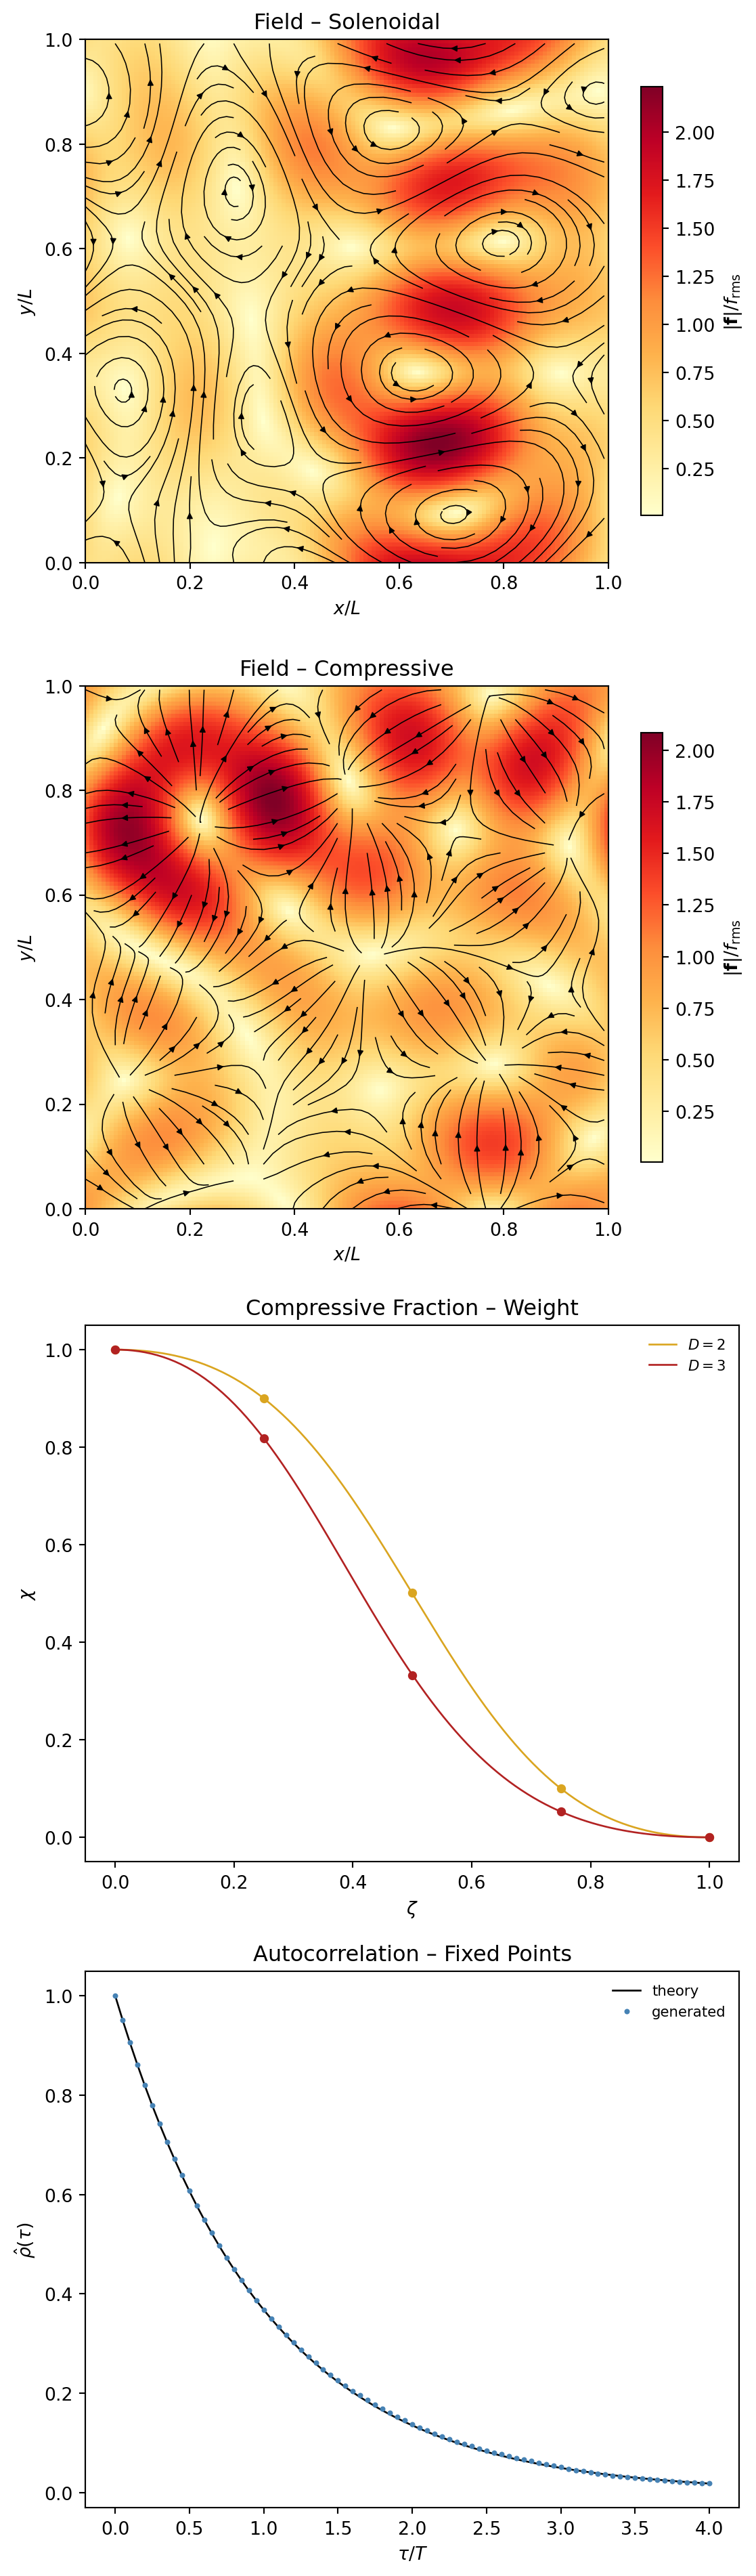

In [15]:
rng = rng_spawn(3)

L, T, dt, frms = 1.0, 1.0, 0.05, 1.0
N, M = 400, 64

n, k, w = forcing_modes(3, L)
g = rng.standard_normal((len(k), 3, 1)) + 1j * rng.standard_normal((len(k), 3, 1))
Ps, Pc = project(projector(k, 1.0), g)[..., 0], project(projector(k, 0.0), g)[..., 0]
assert np.max(np.abs(np.sum(k * Ps, axis=1))) < 1e-12 * np.max(np.abs(k)) * np.max(np.abs(g))
assert np.max(np.abs(np.cross(k, Pc))) < 1e-12 * np.max(np.abs(k)) * np.max(np.abs(g))
P = projector(k, 0.3)
assert np.allclose(P @ P, 0.3**2 * projector(k, 1.0) + 0.7**2 * projector(k, 0.0))

zetas, frac = [0.0, 0.25, 0.5, 0.75, 1.0], {}
for D in (2, 3):
    nD, kD, wD = forcing_modes(D, L)
    G = run_modes(wD, D, T, dt, N, M, rng)
    for zeta in zetas:
        Fh = project(projector(kD, zeta), G)
        pc = np.sum(np.abs(project(projector(kD, 0.0), Fh))**2, axis=(1, 2))   # compressive power per time and member
        pt = np.sum(np.abs(Fh)**2, axis=(1, 2))
        chi, se = batched(lambda Xb: Xb[0].sum() / Xb[1].sum(), np.stack([pc.T, pt.T]))
        assert abs(chi - (1 - zeta)**2 / (1 - 2 * zeta + D * zeta**2)) <= 4 * se + 1e-12
        frac[D, zeta] = chi

G = run_modes(mode_sigma(w, 0.5, 3, frms), 3, T, dt, N, M, rng)
Fh = project(projector(k, 0.5), G)
xp = L * rng.random((8, 3))
f = 2 * np.real(np.einsum("pk,nkim->nmpi", np.exp(1j * xp @ k.T), Fh))   # direct sum at fixed points, members on axis 1
var, se = batched(lambda Xb: np.mean(np.sum(Xb**2, axis=-1)), f)
assert abs(var - frms**2) <= 4 * se
for i in range(3):
    vi, se = batched(lambda Xb: np.mean(Xb[..., i]**2), f)
    assert abs(vi - frms**2 / 3) <= 4 * se
kurt, se = batched(lambda Xb: np.mean(Xb**4) / np.mean(Xb**2)**2, f)
assert abs(kurt - 3) <= 4 * se

kT = int(round(T / dt))
series = f.reshape(N, -1)                                       # columns grouped by member
r1, se = batched(lambda Xb: ensemble_acf(Xb, kT)[kT], series, B=8)
assert abs(r1 - np.exp(-1)) <= 4 * se
rho_f = ensemble_acf(series, 4 * kT)

Ng = 16
snap = Fh[-1][..., 0]
fg = field_grid(snap, n, Ng)
assert np.max(np.abs(fg.imag)) < 1e-10 * np.max(np.abs(fg.real))
xg = L * np.indices((Ng,) * 3).reshape(3, -1).T / Ng
assert np.allclose(field_at(xg, snap, k), fg.real.reshape(3, -1).T)

kg = 2 * np.pi * np.fft.fftfreq(Ng, d=L / Ng)
K = np.array(np.meshgrid(kg, kg, kg, indexing="ij"))
for zeta, op in [(1.0, lambda K, F: np.sum(K * F, axis=0)), (0.0, lambda K, F: np.cross(K, F, axis=0))]:
    F = np.fft.fftn(field_grid(project(projector(k, zeta), G[-1])[..., 0], n, Ng).real, axes=(1, 2, 3))
    assert np.max(np.abs(op(K, F))) < 1e-10 * np.max(np.abs(K)) * np.max(np.abs(F))

n2, k2, w2 = forcing_modes(2, L)
g2 = run_modes(mode_sigma(w2, 1.0, 2, frms), 2, T, dt, 1, 1, rng)[0]   # same snapshot for both projections
Ng2 = 128
x2 = L * np.arange(Ng2) / Ng2
zg = np.linspace(0, 1, 200)
lag_f = np.arange(len(rho_f)) * dt / T

fig, ax = plt.subplots(4, 1, figsize=(6, 20), dpi=96)
for j, (zeta, name) in enumerate([(1.0, "Solenoidal"), (0.0, "Compressive")]):
    f2 = field_grid(project(projector(k2, zeta), g2)[..., 0], n2, Ng2).real
    im = ax[j].imshow(np.hypot(f2[0], f2[1]).T / frms, origin="lower", extent=(0, L, 0, L), cmap="YlOrRd")
    still = np.hypot(f2[0], f2[1]).T < 0.05 * frms   # stop streamlines at near stagnant centres
    ax[j].streamplot(x2, x2, np.ma.masked_where(still, f2[0].T), np.ma.masked_where(still, f2[1].T),
                     color="k", linewidth=0.6, density=1.2, arrowsize=0.7)
    ax[j].set(xlim=(0, L), ylim=(0, L), xlabel="$x/L$", ylabel="$y/L$", title=f"Field – {name}")
    fig.colorbar(im, ax=ax[j], shrink=0.8, label="$|\\mathbf{f}|/f_\\mathrm{rms}$")

for D, c in [(2, "goldenrod"), (3, "firebrick")]:
    ax[2].plot(zg, (1 - zg)**2 / (1 - 2 * zg + D * zg**2), "-", color=c, lw=1, label=f"$D = {D}$")
    ax[2].plot(zetas, [frac[D, z] for z in zetas], "o", color=c, ms=4)
ax[2].set(xlabel="$\\zeta$", ylabel="$\\chi$", title="Compressive Fraction – Weight")
ax[2].legend(fontsize=8, edgecolor="none", handlelength=1.9)

ax[3].plot(lag_f, np.exp(-lag_f), "k-", lw=1, label="theory")
ax[3].plot(lag_f, rho_f, "o", color="steelblue", ms=2, label="generated")
ax[3].set(xlabel="$\\tau/T$", ylabel="$\\hat{\\rho}(\\tau)$", title="Autocorrelation – Fixed Points")
ax[3].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
%config InlineBackend.figure_formats = ["retina"]
plt.show()
%config InlineBackend.figure_formats = ["svg"]

### 4. Energy Injection

#### 4.1. Injection

The forcing does work on the flow at the rate per unit mass

$$\varepsilon = \frac{\langle \rho\,\mathbf{v}\cdot\mathbf{a} \rangle}{\langle \rho \rangle}$$

with the velocity $\mathbf{v}$ and the forcing acceleration $\mathbf{a}$ which reduces to $\langle \mathbf{v}\cdot\mathbf{a} \rangle$ for uniform density, so the injection depends not only on the forcing but also on how the velocity responds to it. As a minimal model of this response we let every component of the velocity relax on a damping time $\tau_\symup{d}$ that stands in for the eddy turnover

$$\frac{dv}{dt} = a - \frac{v}{\tau_\symup{d}}$$

whose solution is a weighted integral over the past forcing

$$v(t) = \int_0^\infty e^{-u/\tau_\symup{d}}\,a(t-u)\,du$$

so that multiplying by $a(t)$ and summing over the statistically identical components turns the injection into an integral over the forcing autocovariance

$$\varepsilon = D\,\langle v(t)\,a(t) \rangle = D\int_0^\infty e^{-u/\tau_\symup{d}}\,C_a(u)\,du = D\,\sigma_a^2\int_0^\infty e^{-u/\tau_\symup{d}}\,e^{-u/T}\,du = D\,\sigma_a^2\,\frac{\tau_\symup{d}\,T}{T + \tau_\symup{d}}$$

for forcing of variance $\sigma_a^2$ and correlation time $T$ in every component. For short correlation times $T \ll \tau_\symup{d}$ the injection approaches

$$\varepsilon \simeq D\,\sigma_a^2\,T$$

which only depends on the noise intensity of the forcing and not on the flow, while for long correlation times $T \gg \tau_\symup{d}$ it approaches

$$\varepsilon \simeq D\,\sigma_a^2\,\tau_\symup{d}$$

and is set by the response of the flow instead. Short correlation times therefore control the injection rate directly, whereas persistent forcing leaves it to the flow. For Gaussian forcing and any response the Novikov theorem generalizes the result to

$$\langle v\,a \rangle = \int_0^\infty C_a(u)\,R(u)\,du$$

with the mean response $R(u) = \langle \delta v(t) / \delta a(t-u) \rangle$ of which the linear damping gives the exponential kernel.

#### 4.2. Balance

Multiplying the damping equation by $v$ and averaging in the stationary state gives

$$\frac{1}{2}\frac{d\langle v^2 \rangle}{dt} = \langle v\,a \rangle - \frac{\langle v^2 \rangle}{\tau_\symup{d}} = 0 \qquad \langle v^2 \rangle = \frac{\tau_\symup{d}\,\varepsilon}{D}$$

so the injection balances the damping and sets the velocity variance of every component. The instantaneous work $v\,a$ fluctuates around its mean and is negative whenever velocity and force point against each other, where both are jointly Gaussian with the correlation coefficient

$$c = \frac{\langle v\,a \rangle}{\sqrt{\langle v^2 \rangle\langle a^2 \rangle}} = \sqrt{\frac{\varepsilon}{D\,\tau_\symup{d}\,\sigma_a^2}} = \sqrt{\frac{T}{T + \tau_\symup{d}}}$$

that follows from the balance in the second step. Writing the standardized velocity as $y = c\,x + s\,z$ with the standardized force $x$ and an independent standard normal $z$ and with $s^2 = 1 - c^2$ the joint distribution of $x$ and $z$ is rotationally symmetric, and the signs of force and velocity differ in two opposite wedges bounded by the lines $x = 0$ and $y = 0$ whose opening angle is the angle $\arccos c$ between their normals, so the fraction of time with negative work becomes

$$P(v\,a < 0) = \frac{2\arccos c}{2\pi} = \frac{1}{\pi}\arccos\sqrt{\frac{T}{T + \tau_\symup{d}}}$$

which approaches $1/2$ in the white limit where the force is uncorrelated with the velocity it meets and vanishes in the persistent limit where the velocity follows the force. The velocity is a first order process driven by another first order process, which in the language of the first section is a $\symup{CAR}(2)$ with the two real roots $-1/T$ and $-1/\tau_\symup{d}$ and returns in the higher order section. Here we simulate the forcing with the exact update and the velocity with a fine fixed step that averages the forcing over each step

$$v_{n+1} = e^{-\Delta t/\tau_\symup{d}}\,v_n + \tau_\symup{d}\left(1 - e^{-\Delta t/\tau_\symup{d}}\right)\frac{a_n + a_{n+1}}{2}$$

whose error is second order in the step and stays far below the statistical noise when the step is small compared to both timescales.

#### 4.3. Discrete Injection

In a simulation the force is held fixed over a step and applied as a kick

$$\mathbf{v}^{n+1} = \mathbf{v}^n + \mathbf{a}^n\,\Delta t$$

which changes the kinetic energy per unit mass by

$$\Delta K = \frac{1}{2}\left|\mathbf{v}^n + \mathbf{a}^n\Delta t\right|^2 - \frac{1}{2}\left|\mathbf{v}^n\right|^2 = \mathbf{v}^n\cdot\mathbf{a}^n\,\Delta t + \frac{1}{2}\left|\mathbf{a}^n\right|^2\Delta t^2 = \frac{\mathbf{v}^n + \mathbf{v}^{n+1}}{2}\cdot\mathbf{a}^n\,\Delta t$$

where the last form shows that the change equals the work done with the time centred velocity. A total energy equation that instead adds the work with the old velocity $\mathbf{v}^n\cdot\mathbf{a}^n\Delta t$ misses the second term, so kinetic and total energy drift apart by half of $|\mathbf{a}^n|^2\Delta t^2$ per step and the difference ends up as spurious internal energy. For a kick followed by exact damping over the step we abbreviate the decay factors of forcing and velocity per step

$$A = e^{-\Delta t/T} \qquad E = e^{-\Delta t/\tau_\symup{d}}$$

so that the velocity before the kick is a sum over past kicks

$$\mathbf{v}^n = \sum_{m=1}^\infty E^m\,\mathbf{a}^{n-m}\,\Delta t \qquad \langle \mathbf{v}^n\cdot\mathbf{a}^n \rangle = D\,\sigma_a^2\,\Delta t\sum_{m=1}^\infty \left(A E\right)^m = D\,\sigma_a^2\,\Delta t\,\frac{A E}{1 - A E}$$

and the mismatch relative to the work with the old velocity becomes

$$\frac{\frac{1}{2}\langle |\mathbf{a}^n|^2 \rangle\,\Delta t^2}{\langle \mathbf{v}^n\cdot\mathbf{a}^n \rangle\,\Delta t} = \frac{1 - A E}{2 A E} \approx \frac{\Delta t}{2}\,\frac{T + \tau_\symup{d}}{T\,\tau_\symup{d}}$$

which is small only if the step is short compared to both the correlation and the damping time, while using the time centred velocity in the energy source removes it exactly. In the white limit the same term is no error at all but the injection itself, since the work with the old velocity then averages to zero and only the self work of the kick remains.

#### 4.4. Momentum

The mode $\mathbf{k} = 0$ is excluded so the force has zero volume average, but the momentum it injects per unit time

$$\frac{d\mathbf{p}}{dt} = \int \rho\,\mathbf{a}\,dV$$

does not vanish once the density varies, since dense regions weight the local force more strongly. Subtracting the density weighted mean at every step

$$\mathbf{a}^\prime = \mathbf{a} - \frac{\int \rho\,\mathbf{a}\,dV}{\int \rho\,dV}$$

removes the net momentum injection exactly, because by construction

$$\int \rho\,\mathbf{a}^\prime\,dV = \int \rho\,\mathbf{a}\,dV - \frac{\int \rho\,\mathbf{a}\,dV}{\int \rho\,dV}\int \rho\,dV = 0$$

while it changes the force only by a spatially uniform acceleration. On a grid the integrals become sums over cells with the density as weight and in a particle code sums over particles with their masses as weight. We test this on a lognormal density built from a Gaussian random field, which is the typical density distribution of supersonic turbulence.

#### 4.5. Scales

The forcing parameters are usually expressed through the turbulent velocity $v_\symup{turb}$ on the driving scale, which defines the eddy turnover time and the Mach number

$$t_\symup{eddy} = \frac{\ell_\symup{d}}{v_\symup{turb}} \qquad \mathcal{M} = \frac{v_\symup{turb}}{c_\symup{s}}$$

with the sound speed $c_\symup{s}$ while in a steady state the injection matches the dissipation of the cascade

$$\varepsilon \sim \frac{v_\symup{turb}^3}{\ell_\symup{d}}$$

which follows from transferring the energy $v_\symup{turb}^2$ once per eddy time. Identifying the damping time with the eddy time and inserting the injection from above gives an estimate of the forcing amplitude for a target velocity

$$D\,\sigma_a^2\,\frac{t_\symup{eddy}\,T}{T + t_\symup{eddy}} \sim \frac{v_\symup{turb}^3}{\ell_\symup{d}} \qquad \sigma_a \sim \frac{v_\symup{turb}^2}{\ell_\symup{d}}\sqrt{\frac{T + t_\symup{eddy}}{D\,T}}$$

so that a target Mach number fixes the amplitude up to a factor of order unity, which in practice is tuned until the measured Mach number settles. Correlation times of about the eddy time are the common choice for driven interstellar turbulence, while codes that need a precisely controlled injection rate use correlation times much shorter than the eddy time. The linear damping only captures how the injection depends on the correlation time, since real turbulence removes energy nonlinearly through the cascade and the spectrum it builds lies beyond this model.

#### 4.6. Tests

We scan the ratio of correlation and damping time and compare the measured injection, velocity variance and fraction of negative work with the predictions, measure the energy mismatch of kicks with the old velocity against its exact discrete form for several steps, check that the time centred work equals the kinetic energy change to round off and verify that the density weighted subtraction removes the net momentum injection while the plain volume average of the force already vanishes.

In [16]:
def ou_filter(T, sigma, dt, N, M, rng):
    """exact update as recursive filter with stationary start, same statistics as ou_exact"""
    A = np.exp(-dt / T)
    xi = rng.standard_normal((N, M))
    return sc.signal.lfilter([sigma * np.sqrt(1 - A**2)], [1, -A], xi, axis=0, zi=A * sigma * rng.standard_normal((1, M)))[0]

def drag_response(a, tau_d, dt):
    """velocity under linear damping with forcing averaged over each step, starts near rest"""
    E = np.exp(-dt / tau_d)
    u = np.concatenate([a[:1], 0.5 * (a[1:] + a[:-1])])
    return sc.signal.lfilter([tau_d * (1 - E)], [1, -E], u, axis=0)

def kick_response(a, tau_d, dt):
    """velocity before each kick when kicks are followed by exact damping, starts at rest"""
    E = np.exp(-dt / tau_d)
    return sc.signal.lfilter([0.0, E * dt], [1, -E], a, axis=0)

def momentum_free(f, w):
    """subtract weighted mean so that force injects no net momentum, weights are density or mass"""
    axes = tuple(range(1, f.ndim))
    return f - np.sum(w * f, axis=axes, keepdims=True) / np.sum(w)

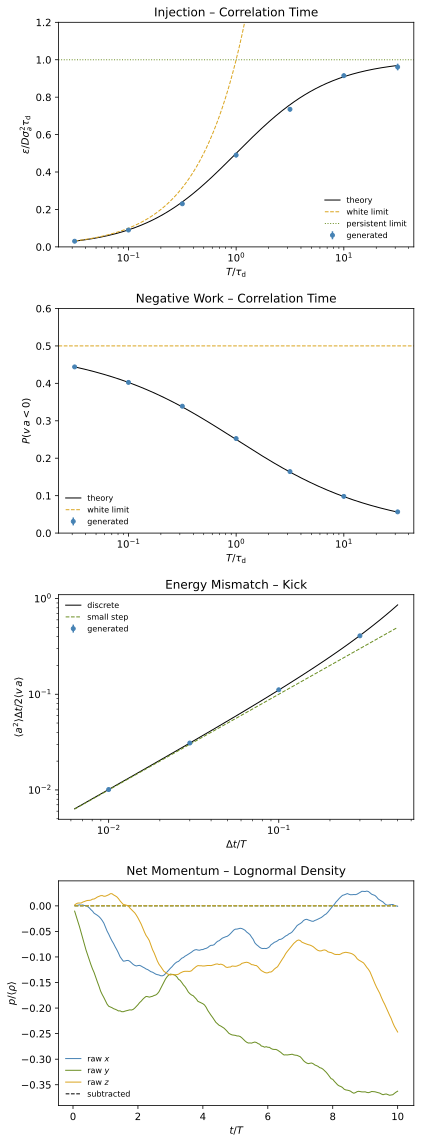

In [17]:
rng = rng_spawn(4)

tau_d, sigma_a, M = 1.0, 1.0, 100
ratios = np.logspace(-1.5, 1.5, 7)
eps_meas, neg_meas = [], []
for r in ratios:
    T = r * tau_d
    dt = min(T, tau_d) / 25
    burn = int(10 * max(T, tau_d) / dt)
    a = ou_filter(T, sigma_a, dt, burn + int(100 * max(T, tau_d) / dt), M, rng)
    v, a = drag_response(a, tau_d, dt)[burn:], a[burn:]
    VA = np.stack([v.T, a.T])                                   # members on axis 1
    eps, se = batched(lambda Xb: np.mean(Xb[0] * Xb[1]), VA)
    v2, se2 = batched(lambda Xb: np.mean(Xb[0]**2), VA)
    eps_th = sigma_a**2 * tau_d * T / (T + tau_d)
    assert abs(eps - eps_th) <= 4 * se and abs(v2 - tau_d * eps_th) <= 4 * se2
    pn, se_n = batched(lambda Xb: np.mean(Xb[0] * Xb[1] < 0), VA)
    assert abs(pn - np.arccos(np.sqrt(T / (T + tau_d))) / np.pi) <= 4 * se_n
    eps_meas.append((eps, se))
    neg_meas.append((pn, se_n))
eps_meas, neg_meas = np.array(eps_meas), np.array(neg_meas)

T = tau_d
steps = np.array([0.01, 0.03, 0.1, 0.3]) * T
mis = []
for d in steps:
    burn = int(10 * T / d)
    a = ou_filter(T, sigma_a, d, burn + int(400 * T / d), M, rng)
    v, a = kick_response(a, tau_d, d)[burn:], a[burn:]
    rm, se = batched(lambda Xb: 0.5 * np.mean(Xb[1]**2) * d / np.mean(Xb[0] * Xb[1]), np.stack([v.T, a.T]))
    AE = np.exp(-d / T - d / tau_d)
    assert abs(rm - (1 - AE) / (2 * AE)) <= 4 * se
    mis.append((rm, se))
    dK = 0.5 * (v + a * d)**2 - 0.5 * v**2
    assert np.allclose(dK, 0.5 * (v + (v + a * d)) * a * d, rtol=1e-12, atol=1e-15)
mis = np.array(mis)

n3, k3, w3 = forcing_modes(3)
Ng, dt_m, Nm = 32, 0.05, 200
gdens = field_grid(project(projector(k3, 1.0), run_modes(w3, 3, 1.0, dt_m, 1, 1, rng)[0])[..., 0], n3, Ng).real[0]
rho = np.exp(gdens / gdens.std() - 0.5)                         # lognormal with unit logarithmic variance
p_raw, p_fix, mean_f = [], [], []
for Fh in project(projector(k3, 0.5), run_modes(mode_sigma(w3, 0.5, 3, 1.0), 3, 1.0, dt_m, Nm, 1, rng))[..., 0]:
    f = field_grid(Fh, n3, Ng).real
    p_raw.append(np.sum(rho * f, axis=(1, 2, 3)) / np.sum(rho))
    p_fix.append(np.sum(rho * momentum_free(f, rho), axis=(1, 2, 3)) / np.sum(rho))
    mean_f.append(np.mean(f, axis=(1, 2, 3)))
p_raw, p_fix = np.cumsum(p_raw, axis=0) * dt_m, np.cumsum(p_fix, axis=0) * dt_m
assert np.max(np.abs(mean_f)) < 1e-12 and np.max(np.abs(p_fix)) < 1e-12 * np.max(np.abs(p_raw))

rg = np.logspace(-1.5, 1.5, 300)
dg = np.logspace(-2.2, np.log10(0.5), 300) * T
AEg = np.exp(-dg / T - dg / tau_d)
tm = dt_m * np.arange(1, Nm + 1)

fig, ax = plt.subplots(4, 1, figsize=(6, 16))
ax[0].semilogx(rg, rg / (1 + rg), "k-", lw=1, label="theory")
ax[0].semilogx(rg, rg, "--", color="goldenrod", lw=1, label="white limit")
ax[0].axhline(1, color="olivedrab", ls=":", lw=1, label="persistent limit")
ax[0].errorbar(ratios, eps_meas[:, 0] / (sigma_a**2 * tau_d), yerr=eps_meas[:, 1] / (sigma_a**2 * tau_d), fmt="o", color="steelblue", ms=4, label="generated")
ax[0].set(ylim=(0, 1.2), xlabel="$T/\\tau_\\mathrm{d}$", ylabel="$\\varepsilon/D\\sigma_a^2\\tau_\\mathrm{d}$", title="Injection – Correlation Time")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9)

ax[1].semilogx(rg, np.arccos(np.sqrt(rg / (1 + rg))) / np.pi, "k-", lw=1, label="theory")
ax[1].axhline(0.5, color="goldenrod", ls="--", lw=1, label="white limit")
ax[1].errorbar(ratios, neg_meas[:, 0], yerr=neg_meas[:, 1], fmt="o", color="steelblue", ms=4, label="generated")
ax[1].set(ylim=(0, 0.6), xlabel="$T/\\tau_\\mathrm{d}$", ylabel="$P(v\\,a < 0)$", title="Negative Work – Correlation Time")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

ax[2].loglog(dg / T, (1 - AEg) / (2 * AEg), "k-", lw=1, label="discrete")
ax[2].loglog(dg / T, dg * (T + tau_d) / (2 * T * tau_d), "--", color="olivedrab", lw=1, label="small step")
ax[2].errorbar(steps / T, mis[:, 0], yerr=mis[:, 1], fmt="o", color="steelblue", ms=4, label="generated")
ax[2].set(xlabel="$\\Delta t/T$", ylabel="$\\langle a^2 \\rangle\\Delta t/2\\langle v\\,a \\rangle$", title="Energy Mismatch – Kick")
ax[2].legend(fontsize=8, edgecolor="none", handlelength=1.9)

for i, (c, comp) in enumerate(zip(["steelblue", "olivedrab", "goldenrod"], "xyz")):
    ax[3].plot(tm, p_raw[:, i], color=c, lw=1, label=f"raw ${comp}$")
    ax[3].plot(tm, p_fix[:, i], "--", color=c, lw=1)
ax[3].plot([], [], "k--", lw=1, label="subtracted")
ax[3].set(xlabel="$t/T$", ylabel="$p/\\langle\\rho\\rangle$", title="Net Momentum – Lognormal Density")
ax[3].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

### 5. Higher Order

#### 5.1. State Space

The general equation of the first section with $p > 1$ is rewritten as a system of first order equations for a latent process $z$ that obeys the autoregressive part alone

$$\alpha(D)\,z = \varepsilon$$

since by linearity the observed process then follows as $x = \beta(D)\,z$ and satisfies $\alpha(D)\,x = \beta(D)\,\alpha(D)\,z = \beta(D)\,\varepsilon$ because the two operators commute. Collecting the latent process and its first $p-1$ derivatives in the state vector

$$X = \left(z,\; z^\prime,\; \dots,\; z^{(p-1)}\right)^\top$$

every component is the derivative of the previous one except the last, whose derivative follows from the equation itself as $z^{(p)} = -\alpha_0 z - \dots - \alpha_{p-1} z^{(p-1)} + \varepsilon$ so that

$$dX = \mathsf{A}\,X\,dt + \mathbf{e}\,\sigma_\varepsilon\,dW \qquad \mathsf{A} = \begin{pmatrix} 0 & 1 & & \\ & \ddots & \ddots & \\ & & 0 & 1 \\ -\alpha_0 & -\alpha_1 & \cdots & -\alpha_{p-1} \end{pmatrix} \qquad x = \mathbf{b}^\top X$$

where $\mathbf{e}$ is the last unit vector and the vector $\mathbf{b}$ holds the coefficients of $\beta$ padded with zeros up to the order of the process. Multiplying by the integrating factor $e^{-\mathsf{A}t}$ exactly as in the first order case

$$d\left(e^{-\mathsf{A}t}X\right) = e^{-\mathsf{A}t}\,\mathbf{e}\,\sigma_\varepsilon\,dW$$

and integrating over one step gives

$$X_{n+1} = \mathsf{F}\,X_n + \boldsymbol{\eta}_n \qquad \mathsf{F} = e^{\mathsf{A}\Delta t} \qquad \boldsymbol{\eta}_n = \sigma_\varepsilon\int_0^{\Delta t} e^{\mathsf{A}(\Delta t - s)}\,\mathbf{e}\,dW(s)$$

where the noise vector is Gaussian and independent of the state and of all other steps, with the covariance

$$\mathsf{Q} = \langle \boldsymbol{\eta}_n\boldsymbol{\eta}_n^\top \rangle = \sigma_\varepsilon^2\int_0^{\Delta t} e^{\mathsf{A}u}\,\mathbf{e}\,\mathbf{e}^\top e^{\mathsf{A}^\top u}\,du$$

that follows from the Itô isometry where we substituted $u = \Delta t - s$ in the last step. Both matrices follow from a single exponential of the block matrix

$$\mathsf{M} = \begin{pmatrix} -\mathsf{A} & \sigma_\varepsilon^2\,\mathbf{e}\,\mathbf{e}^\top \\ 0 & \mathsf{A}^\top \end{pmatrix} \qquad e^{\mathsf{M}t} = \begin{pmatrix} e^{-\mathsf{A}t} & \mathsf{G}(t) \\ 0 & e^{\mathsf{A}^\top t} \end{pmatrix}$$

whose upper right block obeys the upper right block of the derivative of the exponential

$$\frac{d\mathsf{G}}{dt} = -\mathsf{A}\,\mathsf{G} + \sigma_\varepsilon^2\,\mathbf{e}\,\mathbf{e}^\top e^{\mathsf{A}^\top t} \qquad \mathsf{G}(t) = \sigma_\varepsilon^2\int_0^t e^{-\mathsf{A}(t-u)}\,\mathbf{e}\,\mathbf{e}^\top e^{\mathsf{A}^\top u}\,du$$

with the solution by variation of constants, so that the propagator and the noise covariance follow as

$$\mathsf{F} = \left(e^{\mathsf{A}^\top\Delta t}\right)^\top \qquad \mathsf{Q} = \mathsf{F}\,\mathsf{G}(\Delta t)$$

since $e^{\mathsf{A}\Delta t}e^{-\mathsf{A}(\Delta t - u)} = e^{\mathsf{A}u}$ inside the integral. The stationary covariance of the state is the fixed point of the second moment, whose evolution follows from the Itô rule

$$\frac{d\langle X X^\top \rangle}{dt} = \mathsf{A}\,\langle X X^\top \rangle + \langle X X^\top \rangle\,\mathsf{A}^\top + \sigma_\varepsilon^2\,\mathbf{e}\,\mathbf{e}^\top \qquad \mathsf{A}\,\Sigma + \Sigma\,\mathsf{A}^\top + \sigma_\varepsilon^2\,\mathbf{e}\,\mathbf{e}^\top = 0$$

and propagating the state over a lag $\tau$ before projecting gives the autocovariance

$$C(\tau) = \mathbf{b}^\top e^{\mathsf{A}|\tau|}\,\Sigma\,\mathbf{b}$$

which unlike the residue formula holds for repeated roots as well. For a changing step the block exponential has to be recomputed whenever the step changes, which for small orders costs little next to the evaluation of the forcing.

In [18]:
def carma_state_space(alpha, beta):
    """companion matrix, noise vector and observation vector"""
    p = len(alpha)
    A = np.diag(np.ones(p - 1), 1)
    A[-1] = -np.asarray(alpha, dtype=float)
    e, b = np.zeros(p), np.zeros(p)
    e[-1], b[: len(beta)] = 1.0, beta
    return A, e, b

def carma_discretize(A, e, sigma, dt):
    """exact propagator and noise covariance of one step from block exponential"""
    p = len(e)
    Mb = np.zeros((2 * p, 2 * p))
    Mb[:p, :p], Mb[:p, p:], Mb[p:, p:] = -A, sigma**2 * np.outer(e, e), A.T
    E = sc.linalg.expm(Mb * dt)
    F = E[p:, p:].T
    Q = F @ E[:p, p:]
    return F, 0.5 * (Q + Q.T)

def carma_stationary(A, e, sigma):
    """stationary state covariance from lyapunov equation"""
    return sc.linalg.solve_continuous_lyapunov(A, -sigma**2 * np.outer(e, e))

def carma_acov_ss(alpha, beta, sigma, tau):
    """autocovariance from state space, valid for repeated roots"""
    A, e, b = carma_state_space(alpha, beta)
    Sig = carma_stationary(A, e, sigma)
    return np.array([b @ sc.linalg.expm(A * abs(t)) @ Sig @ b for t in np.atleast_1d(tau)])

def tapered_psd(X, dt):
    """periodogram averaged over members with hann taper against leakage"""
    w = np.hanning(X.shape[0])[:, None]
    P = dt / np.sum(w**2) * np.abs(np.fft.rfft(w * X, axis=0))**2
    return np.fft.rfftfreq(X.shape[0], dt), P.mean(axis=1)

def run_carma(alpha, beta, sigma, dt, N, M, rng):
    """exact update of the state for M members over N steps from stationary start, returns observed process"""
    A, e, b = carma_state_space(alpha, beta)
    F, Q = carma_discretize(A, e, sigma, dt)
    sqrtm = lambda C: (lambda w, V: V * np.sqrt(np.clip(w, 0, None)))(*np.linalg.eigh(C))   # symmetric square root factor
    LQ, LS = sqrtm(Q), sqrtm(carma_stationary(A, e, sigma))
    X = LS @ rng.standard_normal((len(e), M))
    out = np.empty((N, M))
    for n in range(N):
        out[n] = b @ X
        X = F @ X + LQ @ rng.standard_normal((len(e), M))
    return out

#### 5.2. Oscillator

With two complex conjugate roots $r = -\gamma \pm i\Omega$ the autoregressive polynomial

$$\alpha(s) = (s + \gamma)^2 + \Omega^2 = s^2 + 2\gamma\,s + \gamma^2 + \Omega^2$$

describes a damped oscillator with damping rate $\gamma$ and frequency $\Omega$ driven by white noise. The residue formula of the first section with $\alpha^\prime(r) = \pm 2i\Omega$ and $\alpha(-r) = 4\gamma(\gamma \mp i\Omega)$ gives conjugate weights whose two modes combine into

$$c_{1,2} = \frac{\sigma_\varepsilon^2\,(\Omega \mp i\gamma)}{8\gamma\Omega\,(\gamma^2 + \Omega^2)} \qquad C(\tau) = C(0)\,e^{-\gamma|\tau|}\left[\cos\Omega\tau + \frac{\gamma}{\Omega}\sin\Omega|\tau|\right] \qquad C(0) = \frac{\sigma_\varepsilon^2}{4\gamma\,(\gamma^2 + \Omega^2)}$$

with the envelope set by the common real part and the integral time by the spectrum at zero frequency

$$T_\symup{env} = \frac{1}{\gamma} \qquad T_\symup{int} = \frac{S(0)}{2\,C(0)} = \frac{\sigma_\varepsilon^2/\alpha_0^2}{2\,C(0)} = \frac{2\gamma}{\gamma^2 + \Omega^2}$$

while the folding time solves $\rho(T_\symup{fold}) = e^{-1}$ without a closed form. For $\Omega \gg \gamma$ the integral time is much shorter than the envelope time, since the positive and negative lobes of the autocorrelation cancel in the area, so the three timescales of the preamble genuinely differ and a correlation time is only meaningful together with its definition. The oscillating autocorrelation also crosses zero long before the envelope has decayed, so the integral time of a measured autocorrelation cannot be truncated at the first zero crossing and is summed over several envelope times instead. With $p - q = 2$ the paths are differentiable and the spectrum falls as $f^{-4}$ at high frequencies.

#### 5.3. Cascade

With two real roots $-1/T_1$ and $-1/T_2$ the polynomial factorizes

$$\alpha(s) = \left(s + \frac{1}{T_1}\right)\left(s + \frac{1}{T_2}\right)$$

and the process is a first order process with time $T_2$ driven by another one with time $T_1$ instead of white noise, which is exactly the velocity of the damping model of the previous section. The residue formula gives two decaying exponentials

$$C(\tau) = \frac{\sigma_\varepsilon^2\,T_1^2\,T_2^2}{2\,(T_1 + T_2)}\;\frac{T_1\,e^{-|\tau|/T_1} - T_2\,e^{-|\tau|/T_2}}{T_1 - T_2} \qquad T_\symup{int} = \frac{S(0)}{2\,C(0)} = T_1 + T_2$$

which stay finite as the two times approach each other, where the difference quotient turns into a derivative and the double root gives

$$C(\tau) = \frac{\sigma_\varepsilon^2\,T^3}{4}\left(1 + \frac{|\tau|}{T}\right)e^{-|\tau|/T}$$

as the state space formula confirms, which is the second analytic test function of the preamble. The residue formula assumed distinct roots and fails at this point, while the state space formula holds for any roots. A forcing of this type is differentiable in time, which removes the kinks of the first order paths within a step at the price of one more state variable per component.

#### 5.4. Moving Average

Adding a moving average coefficient to the oscillator

$$\alpha(D)\,x = \left(1 + \beta_1 D\right)\varepsilon$$

lowers the difference of the orders to one, so the paths lose their differentiability and the spectrum

$$S(f) = \sigma_\varepsilon^2\,\frac{1 + (2\pi f\,\beta_1)^2}{|\alpha(2\pi i f)|^2}$$

returns to the slope $f^{-2}$ at high frequencies while keeping the resonance of the oscillator near its frequency. In the quasar literature this model is known as the damped harmonic oscillator and fitted to light curves as the next step beyond the damped random walk.

#### 5.5. Finite Records

A correlation time measured from a record of duration $L_\symup{r} = N\Delta t$ uses the sample mean $\bar{x}$ in place of the unknown true mean $\mu$ and subtracting it biases the autocovariance estimator. Writing the deviation from the sample mean as $x_n - \bar{x} = (x_n - \mu) - (\bar{x} - \mu)$ and averaging the product at lag $k$ gives

$$\langle (x_{n+k} - \bar{x})(x_n - \bar{x}) \rangle \approx C(k) - \symup{Var}(\bar{x}) \qquad \symup{Var}(\bar{x}) \approx \frac{2\,T_\symup{int}}{L_\symup{r}}\,C(0)$$

where away from the edges of the record each of the two cross terms between a single deviation and the mean contributes the variance of the mean with a negative sign while the square of the mean adds it once, and the variance of the mean is the one derived in the preamble. Dividing by the equally biased variance and abbreviating $\kappa = 2T_\symup{int}/L_\symup{r}$ gives the expected autocorrelation estimate

$$\langle \hat{\rho}(k) \rangle \approx \frac{\rho(k) - \kappa}{1 - \kappa}$$

which pulls the estimate down by an amount that grows with the lag and crosses zero where the true autocorrelation has only decayed to $\kappa$ so far. For the first order process the folding time estimate then solves

$$\frac{e^{-\hat{T}_\symup{fold}/T} - \kappa}{1 - \kappa} = e^{-1} \qquad \hat{T}_\symup{fold} = -T\,\ln\!\left(e^{-1} + \kappa\left(1 - e^{-1}\right)\right)$$

and falls short of the true value unless the record spans many correlation times. This holds for autocovariances averaged over many records before normalizing, while a single record adds a further bias from the ratio of two noisy estimates, and the integral time suffers even more since the noise of a single record also moves its truncation point. A simulation that runs for only a few eddy times measures the correlation time of its own forcing with exactly this bias.

#### 5.6. Tests

We check that the block exponential reproduces the first order coefficients, that the stationary variance from the state space equals the residue weights at zero lag, that residue and state space autocovariances agree for distinct roots and that the double root gives the analytic test function. Simulations with the general exact update test the autocorrelations of oscillator, cascade and moving average model at several lags, the integral and folding times of the oscillator and the integral time of the cascade, together with the high frequency slopes of the periodograms. A periodogram of an untapered record leaks power from low frequencies through sidelobes that fall only as $f^{-2}$ and hides any steeper slope, so for the slopes every record is multiplied by a Hann window $w_n$ before the transform and the result is normalized by $\sum_n w_n^2$ instead of $N$ to keep the expectation equal to the spectrum. Finally ensembles of finite records test the biased autocorrelation and folding time against the predictions.

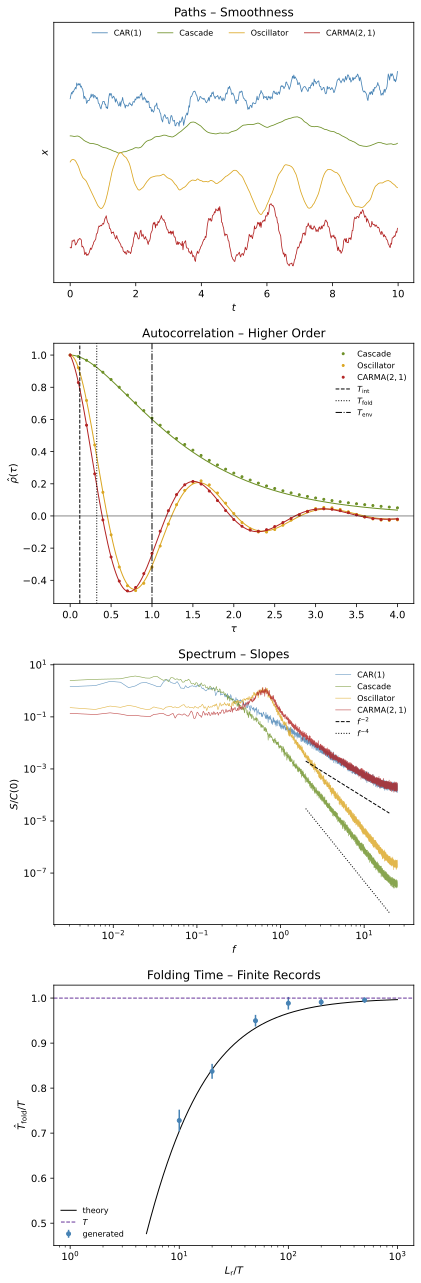

In [19]:
rng = rng_spawn(5)

T = 1.0
F1, Q1 = carma_discretize(*carma_state_space([1 / T], [1.0])[:2], np.sqrt(2 / T), 0.05)
assert np.isclose(F1[0, 0], np.exp(-0.05 / T)) and np.isclose(Q1[0, 0], 1 - np.exp(-0.1 / T))

gam, Om = 1.0, 4.0
osc = ([gam**2 + Om**2, 2 * gam], [1.0], np.sqrt(4 * gam * (gam**2 + Om**2)))   # unit variance oscillator
T1, T2 = 1.0, 0.5
cas = ([1 / (T1 * T2), 1 / T1 + 1 / T2], [1.0], np.sqrt(2 * (T1 + T2) / (T1 * T2)**2))
ma = (osc[0], [1.0, 1 / Om], 1.0)
ma = (ma[0], ma[1], 1 / np.sqrt(carma_acov(*ma, 0.0)))
car1 = ([1 / T], [1.0], np.sqrt(2 / T))
alpha3 = np.poly([-1.0, -0.2 + 2j, -0.2 - 2j]).real[:0:-1]
taus = np.linspace(0, 6, 61)
for proc in [osc, cas, ma, (alpha3, [1.0, 0.5], 1.0)]:
    A, e, b = carma_state_space(*proc[:2])
    assert np.isclose(b @ carma_stationary(A, e, proc[2]) @ b, carma_acov(*proc, 0.0))
    assert np.allclose(carma_acov_ss(*proc, taus), carma_acov(*proc, taus), rtol=1e-7, atol=1e-12)
assert np.allclose(carma_acov_ss([1 / T**2, 2 / T], [1.0], 1.0, taus), T**3 / 4 * (1 + taus / T) * np.exp(-taus / T))

dt, N, M = 0.02, 2**14, 50
lags = np.arange(int(round(4 / gam / dt)) + 1)
sims, rhos = {}, {}
for name, proc in [("car1", car1), ("cascade", cas), ("oscillator", osc), ("moving_average", ma)]:
    X = run_carma(*proc, dt, N, M, rng)
    sims[name] = X
    rhos[name] = ensemble_acf(X, lags[-1])
    if name == "car1":
        continue
    rho_th = carma_acov(*proc, lags * dt) / carma_acov(*proc, 0.0)
    for kk in [int(round(np.pi / (2 * Om * dt))), int(round(np.pi / (Om * dt))), int(round(1 / (gam * dt)))]:
        rk, se = batched(lambda Xb: ensemble_acf(Xb, kk)[kk], X)
        assert abs(rk - rho_th[kk]) <= 4 * se

rho_osc = lambda t: np.exp(-gam * t) * (np.cos(Om * t) + gam / Om * np.sin(Om * t))
t_fold_th = sc.optimize.brentq(lambda t: rho_osc(t) - np.exp(-1), 0, np.pi / (2 * Om))
ti, se = batched(lambda Xb: integral_time(ensemble_acf(Xb, int(8 / (gam * dt))), dt, stop_at_first_zero=False), sims["oscillator"])
assert abs(ti - 2 * gam / (gam**2 + Om**2)) <= 4 * se
tf, se = batched(lambda Xb: fold_time(ensemble_acf(Xb, lags[-1]), dt), sims["oscillator"])
assert abs(tf - t_fold_th) <= 4 * se
ti, se = batched(lambda Xb: integral_time(ensemble_acf(Xb, int(10 * T1 / dt)), dt, stop_at_first_zero=False), sims["cascade"])
assert abs(ti - (T1 + T2)) <= 4 * se

psd, slopes = {}, {}
for name, proc, expected in [("car1", car1, -2), ("cascade", cas, -4), ("oscillator", osc, -4), ("moving_average", ma, -2)]:
    f, P = tapered_psd(sims[name], dt)
    psd[name] = P
    band = (f > 4) & (f < 8)
    slope = np.polyfit(np.log(f[band]), np.log(P[band]), 1)[0]
    slope_th = np.polyfit(np.log(f[band]), np.log(carma_psd(*proc, f[band])), 1)[0]
    assert abs(slope - slope_th) < 0.15 and abs(slope_th - expected) < 0.2
    slopes[name] = slope

dtr, Mr = 0.05, 400
lengths = np.array([10, 20, 50, 100, 200, 500])
fr = []
for Lr in lengths:
    Xr = ou_filter(T, 1.0, dtr, int(Lr * T / dtr), Mr, rng)
    Xr -= Xr.mean(axis=0)                                       # sample mean of every record
    kap, kT = 2 * T / (Lr * T), int(round(T / dtr))
    rk, se_r = batched(lambda Xb: ensemble_acf(Xb, kT)[kT], Xr, B=20)
    tf, se_f = batched(lambda Xb: fold_time(ensemble_acf(Xb, 3 * kT), dtr), Xr, B=20)
    assert abs(rk - (np.exp(-1) - kap) / (1 - kap)) <= 4 * se_r
    assert abs(tf + T * np.log(np.exp(-1) + kap * (1 - np.exp(-1)))) <= 4 * se_f
    fr.append((tf, se_f))
fr = np.array(fr)

styles = {"car1": ("steelblue", "$\\mathrm{CAR}(1)$"), "cascade": ("olivedrab", "Cascade"),
          "oscillator": ("goldenrod", "Oscillator"), "moving_average": ("firebrick", "$\\mathrm{CARMA}(2,1)$")}
tw = dt * np.arange(int(10 / dt))
Lg = np.logspace(np.log10(5), np.log10(1000), 300)
kg = 2 / Lg

fig, ax = plt.subplots(4, 1, figsize=(6, 18))
for j, (name, (c, lab)) in enumerate(styles.items()):
    ax[0].plot(tw, sims[name][: len(tw), 0] / sims[name].std() - 4 * j, color=c, lw=0.8, label=lab)
ax[0].set(yticks=[], ylim=(-16, 6), xlabel="$t$", ylabel="$x$", title="Paths – Smoothness")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9, loc="upper center", ncol=4)

for name, proc in [("cascade", cas), ("oscillator", osc), ("moving_average", ma)]:
    c, lab = styles[name]
    ax[1].plot(lags * dt, carma_acov(*proc, lags * dt) / carma_acov(*proc, 0.0), "-", color=c, lw=1)
    ax[1].plot(lags[::5] * dt, rhos[name][::5], "o", color=c, ms=2, label=lab)
ax[1].axhline(0, color="k", lw=0.5)
ax[1].axvline(2 * gam / (gam**2 + Om**2), color="k", ls="--", lw=1, label="$T_\\mathrm{int}$")
ax[1].axvline(t_fold_th, color="k", ls=":", lw=1, label="$T_\\mathrm{fold}$")
ax[1].axvline(1 / gam, color="k", ls="-.", lw=1, label="$T_\\mathrm{env}$")
ax[1].set(xlabel="$\\tau$", ylabel="$\\hat{\\rho}(\\tau)$", title="Autocorrelation – Higher Order")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

for name, (c, lab) in styles.items():
    ax[2].loglog(f[1:], psd[name][1:] / sims[name].var(), color=c, lw=0.6, alpha=0.8, label=lab)
fg = np.array([2.0, 20.0])
ax[2].loglog(fg, 2e-3 * (fg / 2)**-2, "k--", lw=1, label="$f^{-2}$")
ax[2].loglog(fg, 3e-5 * (fg / 2)**-4, "k:", lw=1, label="$f^{-4}$")
ax[2].set(xlabel="$f$", ylabel="$S/C(0)$", title="Spectrum – Slopes")
ax[2].legend(fontsize=8, edgecolor="none", handlelength=1.9)

ax[3].semilogx(Lg, -np.log(np.exp(-1) + kg * (1 - np.exp(-1))), "k-", lw=1, label="theory")
ax[3].errorbar(lengths, fr[:, 0] / T, yerr=fr[:, 1] / T, fmt="o", color="steelblue", ms=4, label="generated")
ax[3].axhline(1, color="rebeccapurple", ls="--", lw=1, label="$T$")
ax[3].set(xlabel="$L_\\mathrm{r}/T$", ylabel="$\\hat{T}_\\mathrm{fold}/T$", title="Folding Time – Finite Records")
ax[3].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

### 6. Literature

#### 6.1. Spectral Forcing

Stochastic forcing of a few low wavenumber modes goes back to [Eswaran 1988] who designed a spectral scheme that keeps isotropic turbulence statistically stationary in direct numerical simulations and found that the details of the forcing do not significantly affect the small scale structure. [Alvelius 1999] built the force from fully random modes in a shell at small wavenumbers and removed the correlation between force and velocity, so that the injected power is fixed in advance and balances a prescribed dissipation, which is the white limit of the injection section turned into a design principle.

#### 6.2. Astrophysical Driving

[Schmidt 2006] wrote the driving as a three component first order process in Fourier space with the weighted projector of the forcing section, so that the weight $\zeta$ sets the mixture of solenoidal and compressive modes. [Federrath 2008] compared purely solenoidal and purely compressive driving at the same Mach number and found a much wider density distribution for compressive driving, and noted that driving with a static pattern is the limit of an infinite correlation time. [Federrath 2010] set up what became the reference configuration, with the parabolic profile on $1 < kL/2\pi < 3$ and a correlation time equal to the eddy time $T = L/2v_\symup{turb}$ at the peak of the profile, and wrote the projector as $\zeta\,\delta_{ij} + (1 - 2\zeta)\,k_i k_j/k^2$ which equals ours after expanding the perpendicular projector. The same work derived the compressive fraction of the forcing section for general dimension and noted that the natural mixture at $\zeta = 1/2$ gives $\chi = 1/3$ in three dimensions. It further relates the forcing to the width of the density distribution through

$$\frac{\sigma_\rho}{\langle\rho\rangle} = b\,\mathcal{M} \qquad \sigma_s^2 = \ln\!\left(1 + b^2\mathcal{M}^2\right) \qquad s = \ln\frac{\rho}{\langle\rho\rangle}$$

with a parameter $b$ that depends on the driving through the fit

$$\tilde{b}(\zeta) = \frac{1}{D} + \frac{D - 1}{D}\,\chi(\zeta)^3$$

which runs from $\tilde{b} = 1/D$ for solenoidal to $\tilde{b} = 1$ for compressive driving and uses exactly the compressive fraction derived above. [Federrath 2022] is the public implementation of this configuration, a module that generates the time sequence of Fourier modes through the first order process and comes with plugins for several hydrodynamics codes.

#### 6.3. Particles and Grids

[Price 2010] compared driven supersonic isothermal turbulence in a grid code and in a smoothed particle hydrodynamics code and found good agreement in the basic statistics once the number of particles roughly equals the number of cells, a more dissipative velocity field in the particle code which in turn resolved dense structures better, and the need for a stronger nonlinear artificial viscosity to prevent particle interpenetration in strong shocks. It is the closest published analogue to driving both solvers of SHAMROCK with the same forcing.

#### 6.4. Galaxy Scale

[Brucy 2020] simulated kiloparsec sections of galactic disks with stellar feedback and found that feedback regulates star formation in conditions like the Milky Way but not in gas rich galaxies at high redshift, where an additional large scale turbulent driving within the disk plane in the style of [Schmidt 2009] can bring the star formation rate down to the observed relation. [Brucy 2023] added magnetic fields and found that the outcome depends strongly on the field strength and on the compressibility of the driving, and discussed gravitational instabilities, accretion and supernovae as physical sources of such large scale driving.

#### 6.5. Light Curves

[Kelly 2009] modeled optical quasar light curves as a first order continuous process and found characteristic timescales and amplitudes that correlate with black hole mass and luminosity, which established the damped random walk as the standard model. [Kelly 2014] generalized this to CARMA models whose spectra are sums of Lorentzians and whose likelihood handles irregular sampling, and [Moreno 2019] reviewed these models with the damped harmonic oscillator as the next order, stressing that CARMA timescales describe correlation structure rather than physical timescales and that the record length limits their estimation. [Kozłowski 2016] showed that light curves generated by other processes are fitted equally well by a damped random walk, so a good fit does not prove the model and the recovered timescale is biased, and [Kozłowski 2017] found that the record has to span $L_\symup{r} \geq 10\,\tau$ for reliable parameters of the damped random walk, which is the finite record bias of the higher order section in its published form.

#### 6.6. Alternatives

A static driving pattern is the limit of infinite correlation time within the same framework, while localized injection in real space such as explicit supernovae is more realistic but harder to characterize by a correlation time, a scale and a mixture, which is why controlled studies keep the Fourier driving. Non Gaussian or nonlinear driving processes add parameters without an obvious physical constraint on them, while the statistics of the flow are mostly set by the cascade, so the Gaussian first order process with its controllable correlation time remains the default choice.

[Eswaran 1988]: https://doi.org/10.1016/0045-7930%2888%2990013-8
[Alvelius 1999]: https://doi.org/10.1063/1.870050
[Schmidt 2006]: https://arxiv.org/abs/astro-ph/0407616
[Schmidt 2009]: https://doi.org/10.1051/0004-6361:200809967
[Federrath 2008]: https://doi.org/10.1086/595280
[Federrath 2010]: https://doi.org/10.1051/0004-6361/200912437
[Federrath 2022]: https://www.ascl.net/2204.001
[Price 2010]: https://doi.org/10.1111/j.1365-2966.2010.16810.x
[Brucy 2020]: https://doi.org/10.3847/2041-8213/ab9830
[Brucy 2023]: https://doi.org/10.1051/0004-6361/202244915
[Kelly 2009]: https://arxiv.org/abs/0903.5315
[Kelly 2014]: https://doi.org/10.1088/0004-637X/788/1/33
[Moreno 2019]: https://doi.org/10.1088/1538-3873/ab1597
[Kozłowski 2016]: https://doi.org/10.1093/mnras/stw819
[Kozłowski 2017]: https://doi.org/10.1051/0004-6361/201629890

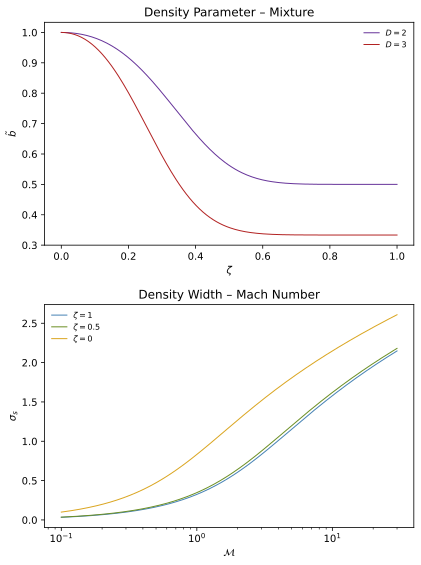

In [20]:
def b_fit(zeta, D):
    """density variance parameter from the fit of Federrath 2010"""
    chi = (1 - zeta)**2 / (1 - 2 * zeta + D * zeta**2)
    return 1 / D + (D - 1) / D * chi**3

chi_of = lambda zeta, D: (1 - zeta)**2 / (1 - 2 * zeta + D * zeta**2)
assert np.isclose(chi_of(0.5, 3), 1 / 3) and np.isclose(chi_of(0.5, 2), 1 / 2)
for D in (2, 3):
    assert np.isclose(b_fit(1.0, D), 1 / D) and np.isclose(b_fit(0.0, D), 1.0)

zg = np.linspace(0, 1, 200)
Mg = np.logspace(-1, np.log10(30), 200)

fig, ax = plt.subplots(2, 1, figsize=(6, 8))
for D, c in [(2, "rebeccapurple"), (3, "firebrick")]:
    ax[0].plot(zg, b_fit(zg, D), "-", color=c, lw=1, label=f"$D = {D}$")
ax[0].set(xlabel="$\\zeta$", ylabel="$\\tilde{b}$", title="Density Parameter – Mixture")
ax[0].legend(fontsize=8, edgecolor="none", handlelength=1.9)

for zeta, c in [(1.0, "steelblue"), (0.5, "olivedrab"), (0.0, "goldenrod")]:
    ax[1].semilogx(Mg, np.sqrt(np.log(1 + b_fit(zeta, 3)**2 * Mg**2)), "-", color=c, lw=1, label=f"$\\zeta = {zeta:g}$")
ax[1].set(xlabel="$\\mathcal{M}$", ylabel="$\\sigma_s$", title="Density Width – Mach Number")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
plt.show()

### 7. SHAMROCK

#### 7.1. Hooks

Both solvers already accept external forces through a variant of force types in their configuration. In the Godunov solver the configuration `ExtForceConfig` holds a list of forces, currently constant gravity only, which fill the acceleration `a_ext` of every cell, and the module `ApplyExtForceGas` couples it to the conservative state with either the explicit midpoint rule or the trapezoidal rule. In the particle solver the method `compute_ext_forces_indep_v` runs once per step for forces that do not depend on the velocity and writes the field `axyz_ext` while `add_ext_forces` adds velocity dependent forces to the acceleration. A stochastic forcing does not depend on the velocity, so in both solvers it becomes one more entry of the force variant that is evaluated once per step from the current mode amplitudes.

#### 7.2. State

The mode amplitudes are global and few, so every process keeps an identical copy and advances it once per full step with the exact update, which keeps the statistics independent of the history of step sizes as shown in the time stepping section. To keep the copies identical without communication the random draws of every step come from a generator keyed by the seed and the step number alone, which also makes a run independent of the domain decomposition and reproducible bit by bit. The amplitudes and the step counter belong into every checkpoint since a restart would otherwise begin a new realization, and a step that is rejected and retried with a smaller size has to restore the amplitudes as well.

#### 7.3. Evaluation

With few modes the force at a particle or cell centre follows from the direct sum of the forcing section, which costs a number of operations proportional to the number of modes per point and needs no auxiliary grid, so the same evaluation serves particles and adaptive meshes alike. The phase factors of all modes follow from the phase factors of the base wavevectors by repeated multiplication since every wavevector is an integer combination of them, which replaces most trigonometric evaluations by complex products. The sum over modes is carried out separately for every point in a fixed order, so the result does not depend on how the points are grouped or distributed.

#### 7.4. Bookkeeping

The bookkeeping of the injection section carries over directly. The force is reduced by its mass weighted mean once per step with a single global reduction, which removes the net momentum injection with particle masses as weights in the particle solver and with cell masses in the Godunov solver. The energy source should use the time centred momentum including half of the forcing kick, since the midpoint coupling currently adds the work done with the momentum before the kick, and the comment in `ApplyExtForceGas` already points to the resulting drift of the internal energy by about half of $\rho\,a^2\Delta t^2$ per step that the discrete injection section derives. The forcing is held fixed across the stages of a step so that a multistage integrator never draws new noise within a step.

#### 7.5. Interface

A forcing entry in the configuration needs the correlation time, the weight $\zeta$ and the profile with driving scale and width, the amplitude or a target Mach number, the seed and the stepping scheme. The exact update is the default, alternative linear schemes only supply the coefficients $a$ and $b$ of one step as in the time stepping section, and higher order processes fit the same interface by supplying the propagator and the noise covariance of the state space section.

#### 7.6. Validation

The tests of this notebook translate into unit tests of the implementation, covering the stationary variance and correlation time of the modes, the compressive fraction against the weight, the injection rate in a damped test problem, the vanishing net momentum and the determinism across decompositions and restarts. The reference class below has the structure intended for the code and tests the last two properties, together with an independence of the force from the grouping of the points.

In [21]:
class ForcingField:
    """forcing field with exact mode update and draws keyed by seed and step"""

    def __init__(self, D, L, T, zeta, frms, seed, nd=2.0, dn=1.0):
        self.n, self.k, w = forcing_modes(D, L, nd, dn)
        self.P = projector(self.k, zeta)
        self.s = mode_sigma(w, zeta, D, frms)
        self.T, self.seed, self.count = T, seed, 0
        self.g = self.s[:, None] * self._draw(0)                # stationary start

    def _draw(self, key):
        """complex standard normals for all modes from seed and key alone"""
        rng = np.random.default_rng([self.seed, key])
        shape = self.k.shape
        return rng.standard_normal(shape) + 1j * rng.standard_normal(shape)

    def step(self, dt):
        """exact update of all amplitudes over one step"""
        A = np.exp(-dt / self.T)
        self.count += 1
        self.g = A * self.g + self.s[:, None] * np.sqrt(1 - A**2) * self._draw(self.count)

    def eval_at(self, x):
        """force at points of shape (P, D) with one reduction per point"""
        Fh = np.einsum("kij,kj->ki", self.P, self.g)
        phase = np.exp(1j * (x @ self.k.T))
        return 2 * np.real(np.sum(phase[:, :, None] * Fh[None], axis=1))

    def state(self):
        """amplitudes and step counter for a checkpoint"""
        return {"g": self.g.copy(), "count": self.count}

    def restore(self, st):
        """continue from a checkpoint"""
        self.g, self.count = st["g"].copy(), st["count"]

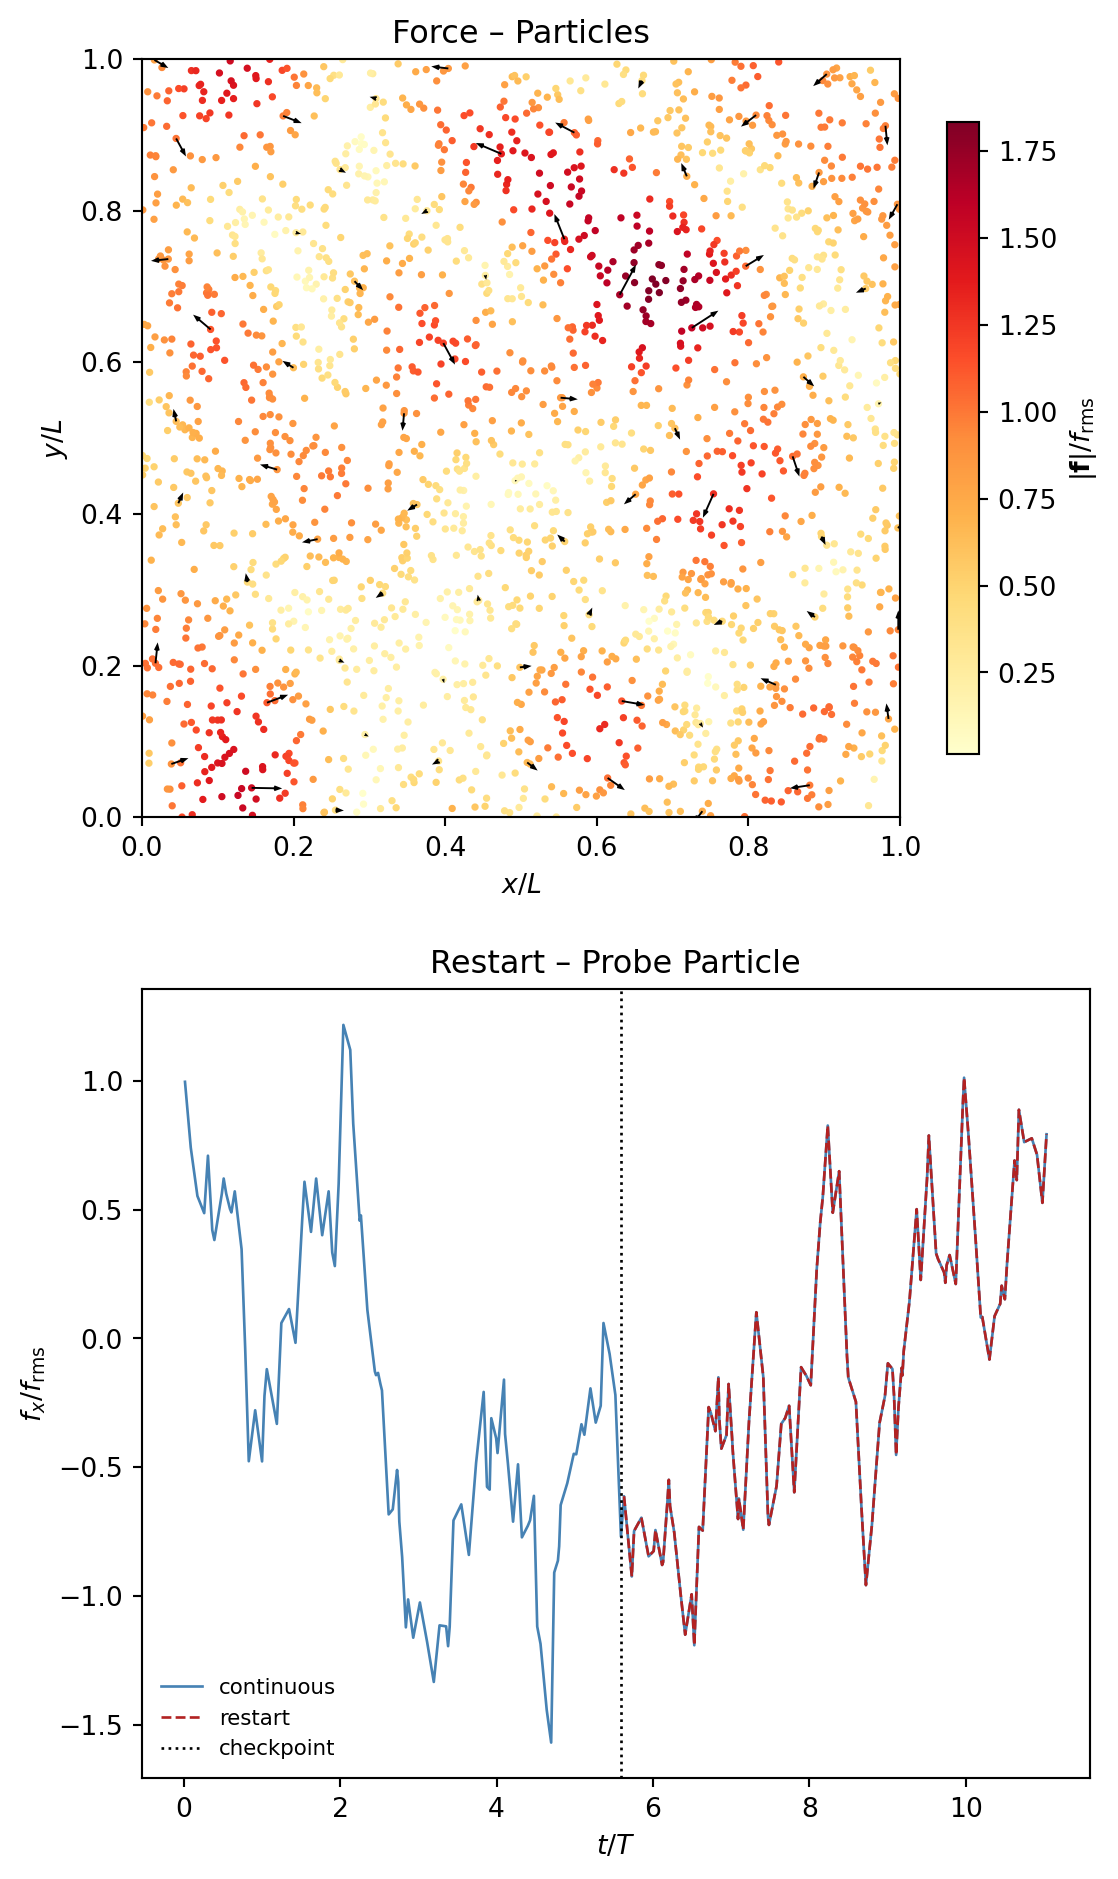

In [22]:
rng = rng_spawn(7)

D, L, T, frms, seed = 2, 1.0, 1.0, 1.0, 2026
dts = T * rng.uniform(0.01, 0.1, 200)                           # variable step sizes
xp = L * rng.random((2000, D))
mp = rng.uniform(0.5, 1.5, len(xp))                             # unequal particle masses

ranks = [ForcingField(D, L, T, 0.5, frms, seed) for _ in range(2)]
probe, ckpt = [], None
for i, dt in enumerate(dts):
    for f in ranks:
        f.step(dt)
    probe.append(ranks[0].eval_at(xp[:1])[0])
    if i == 99:
        ckpt = ranks[0].state()
assert np.array_equal(ranks[0].g, ranks[1].g)

restarted = ForcingField(D, L, T, 0.5, frms, seed)
restarted.restore(ckpt)
probe_r = []
for dt in dts[100:]:
    restarted.step(dt)
    probe_r.append(restarted.eval_at(xp[:1])[0])
assert np.array_equal(restarted.g, ranks[0].g)

f_all = ranks[0].eval_at(xp)
perm = rng.permutation(len(xp))
f_perm = np.empty_like(f_all)
f_perm[perm] = ranks[0].eval_at(xp[perm])
f_split = np.concatenate([ranks[0].eval_at(part) for part in np.array_split(xp, 7)])
assert np.array_equal(f_all, f_perm) and np.array_equal(f_all, f_split)

f_free = momentum_free(f_all.T, mp).T
assert np.max(np.abs(mp @ f_all)) > 1e-3 and np.max(np.abs(mp @ f_free)) < 1e-12 * np.sum(mp)

probe, probe_r = np.array(probe), np.array(probe_r)
t_all = np.cumsum(dts)

fig, ax = plt.subplots(2, 1, figsize=(6, 10), dpi=96)
mag = np.hypot(f_free[:, 0], f_free[:, 1])
sc_ = ax[0].scatter(xp[:, 0], xp[:, 1], c=mag / frms, s=3, cmap="YlOrRd")
dmin, keep = 0.1, []
for j in range(len(xp)):                                        # greedy subset with minimum spacing
    if all(np.hypot(*(xp[j] - xp[q])) >= dmin for q in keep):
        keep.append(j)
lmax = 0.45 * dmin                                              # arrows shorter than half the spacing cannot cross
ax[0].quiver(xp[keep, 0], xp[keep, 1], f_free[keep, 0], f_free[keep, 1], color="k", width=0.0025, headwidth=3, headlength=4,
             angles="xy", scale_units="xy", scale=np.max(np.hypot(f_free[keep, 0], f_free[keep, 1])) / lmax)
ax[0].set(xlim=(0, L), ylim=(0, L), aspect="equal", xlabel="$x/L$", ylabel="$y/L$", title="Force – Particles")
fig.colorbar(sc_, ax=ax[0], shrink=0.8, label="$|\\mathbf{f}|/f_\\mathrm{rms}$")

ax[1].plot(t_all / T, probe[:, 0] / frms, color="steelblue", lw=1, label="continuous")
ax[1].plot(t_all[100:] / T, probe_r[:, 0] / frms, "--", color="firebrick", lw=1, label="restart")
ax[1].axvline(t_all[99] / T, color="k", ls=":", lw=1, label="checkpoint")
ax[1].set(xlabel="$t/T$", ylabel="$f_x/f_\\mathrm{rms}$", title="Restart – Probe Particle")
ax[1].legend(fontsize=8, edgecolor="none", handlelength=1.9)

fig.tight_layout()
%config InlineBackend.figure_formats = ["retina"]
plt.show()
%config InlineBackend.figure_formats = ["svg"]